# Figures for the Doolittle-Kraemer skill diagram paper

Extracted from `verification_figures_for_harold.ipynb`. Each code cell below is copied **verbatim** from that notebook
(original cell number in the heading), except the cells marked **[added]**, which only save figures to files.

| Paper figure | Source cell(s) |
|---|---|
| Fig. 1 (ROC + performance diagrams, systems A and B) | 106 (top row of its 2x2 figure) |
| Fig. 2 (skill space, systems A and B) | 106 (bottom-right panel) |
| Fig. 3, top row (x̄ = 0.1) | 213 |
| Fig. 3, bottom row (x̄ = 0.33) | 219 |

Supporting cells: 0 (imports), 51 (α-axis helper functions), 93 (`df1`, used only for the dot at the origin in Fig. 2),
101 and 102 (systems A and B: forecast/observation pairs and 10 000 bootstrap resamples).

Notes:
- The bootstrap (cells 101, 102) and the Fig. 3 bottom-row curves (cell 219) use `rng = default_rng()` with no seed,
  so error bars and the x̄ = 0.33 curves differ slightly on each run.
- Figure files are written to `figures/` next to this notebook.

## Imports (original cell 0)

In [1]:
import matplotlib.pyplot as plt 
#import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import beta,norm,zscore,entropy
import matplotlib.patches as patches
import matplotlib.colors as colors
%matplotlib inline
from numpy.random import default_rng
from scipy.interpolate import griddata,RegularGridInterpolator
from sklearn import metrics
#from scipy import interpolate
rng = default_rng()

In [2]:
# [added] output folder for figure files
import os
os.makedirs('figures', exist_ok=True)

## Secondary-axis helper functions for α_lower / α_upper (original cell 51)

In [3]:
def srp2sr01(x):
    return 0.01 + x*(1.-0.01)

def sr2srp01(x):
    return (x-0.01)/(1.-0.01)

def podp2mr01(x):
    return 0.01*(1.-x)

def mr2podp01(x):
    return (0.01-x)/0.01


def srp2sr10(x):
    return 0.10 + x*(1.-0.10)

def sr2srp10(x):
    return (x-0.10)/(1.-0.10)

def podp2mr10(x):
    return 0.10*(1.-x)

def mr2podp10(x):
    return (0.10-x)/0.10


def srp2sr25(x):
    return 0.25 + x*(1.-0.25)

def sr2srp25(x):
    return (x-0.25)/(1.-0.25)

def podp2mr25(x):
    return 0.25*(1.-x)

def mr2podp25(x):
    return (0.25-x)/0.25


def srp2sr33(x):
    return 0.33 + x*(1.-0.33)

def sr2srp33(x):
    return (x-0.33)/(1.-0.33)

def podp2mr33(x):
    return 0.33*(1.-x)

def mr2podp33(x):
    return (0.33-x)/0.33

## `df1` (original cell 93)
Only the `zero` column is used, for the red dot at the origin of Fig. 2.

In [4]:
data1 = {
    'phi': [0.4, 0.4, 0.4],
    'xbar': [0.1, 0.35, 0.01],
    'zero': [0.0, 0.0, 0.0],
    'bias': [1.35, 1.2, 1.55]
}

df1= pd.DataFrame(data1)

## Forecast system A: pairs and bootstrap (original cell 101)

In [5]:
# fcst = 1 for yes, 0 for no
# obs = 1 for yes, 0 for no
# arrays hold pairs of fcst/obs
fcst=np.zeros(1000)
obs=np.zeros(1000)
#fcst[0:4025]=1.
#obs[0:2344]=1.
#bs[4026:5182]=1.
fcst[0:420]=1.
obs[0:241]=1.
obs[421:530]=1.
#
n_size=fcst.shape[0]
dfa = pd.DataFrame({'fcst': fcst, 'obs': obs})
# get elements of contingency table into dataframe
# a=TP, b=FP, c=FN, d=TN, easy to compute if these are binary arrays
dfa['a']=dfa['fcst']*dfa['obs']
dfa['b']=dfa['fcst']*(1.-dfa['obs'])
dfa['c']=(1.-dfa['fcst'])*dfa['obs']
dfa['d']=(1.-dfa['fcst'])*(1.-dfa['obs'])
# number of bootstrap iterations set up arrays to hold stats for each iteration
n_repeat=10000
poda=np.zeros(n_repeat)
sra=np.zeros(n_repeat)
fbara=np.zeros(n_repeat)
xbara=np.zeros(n_repeat)
pofda=np.zeros(n_repeat)
biasa=np.zeros(n_repeat)
pod_skilla=np.zeros(n_repeat)
sr_skilla=np.zeros(n_repeat)
for i in np.arange(n_repeat):
    df_rand=dfa.sample(n_size,replace=True) # resample with replacement
    a=df_rand['a'].sum()
    b=df_rand['b'].sum()
    c=df_rand['c'].sum()
    d=df_rand['d'].sum()
    biasa[i]=(a+b)/(a+c)
    poda[i]=a/(a+c)
    fbara[i]=(a+b)/(a+b+c+d)
    xbara[i]=(a+c)/(a+b+c+d)
    sra[i]=a/(a+b)
    pofda[i]=b/(b+d)
    pod_skilla[i]=(a*d-b*c)/(a+c)/(c+d)
    sr_skilla[i]=(a*d-b*c)/(a+b)/(b+d)

## Forecast system B: pairs and bootstrap (original cell 102)

In [6]:
# fcst = 1 for yes, 0 for no
# obs = 1 for yes, 0 for no
# arrays hold pairs of fcst/obs
fcst=np.zeros(1000)
obs=np.zeros(1000)
# fcst[0:1250]=1.
# obs[0:522]=1.
# obs[1251:1729]=1.
fcst[0:135]=1.
obs[0:55]=1.
obs[136:181]=1.
#
n_size=fcst.shape[0]
dfb = pd.DataFrame({'fcst': fcst, 'obs': obs})
# get elements of contingency table into dataframe
# a=TP, b=FP, c=FN, d=TN, easy to compute if these are binary arrays
dfb['a']=dfb['fcst']*dfb['obs']
dfb['b']=dfb['fcst']*(1.-dfb['obs'])
dfb['c']=(1.-dfb['fcst'])*dfb['obs']
dfb['d']=(1.-dfb['fcst'])*(1.-dfb['obs'])
# number of bootstrap iterations set up arrays to hold stats for each iteration
n_repeat=10000
podb=np.zeros(n_repeat)
srb=np.zeros(n_repeat)
fbarb=np.zeros(n_repeat)
xbarb=np.zeros(n_repeat)
pofdb=np.zeros(n_repeat)
biasb=np.zeros(n_repeat)
pod_skillb=np.zeros(n_repeat)
sr_skillb=np.zeros(n_repeat)
for i in np.arange(n_repeat):
    df_rand=dfb.sample(n_size,replace=True) # resample with replacement
    a=df_rand['a'].sum()
    b=df_rand['b'].sum()
    c=df_rand['c'].sum()
    d=df_rand['d'].sum()
    biasb[i]=(a+b)/(a+c)
    podb[i]=a/(a+c)
    fbarb[i]=(a+b)/(a+b+c+d)
    xbarb[i]=(a+c)/(a+b+c+d)
    srb[i]=a/(a+b)
    pofdb[i]=b/(b+d)
    pod_skillb[i]=(a*d-b*c)/(a+c)/(c+d)
    sr_skillb[i]=(a*d-b*c)/(a+b)/(b+d)

## Figs. 1 and 2 (original cell 106)
Top row = Fig. 1; bottom-right panel = Fig. 2. The bottom-left panel (BIAS/ρ space) is not used in the paper.

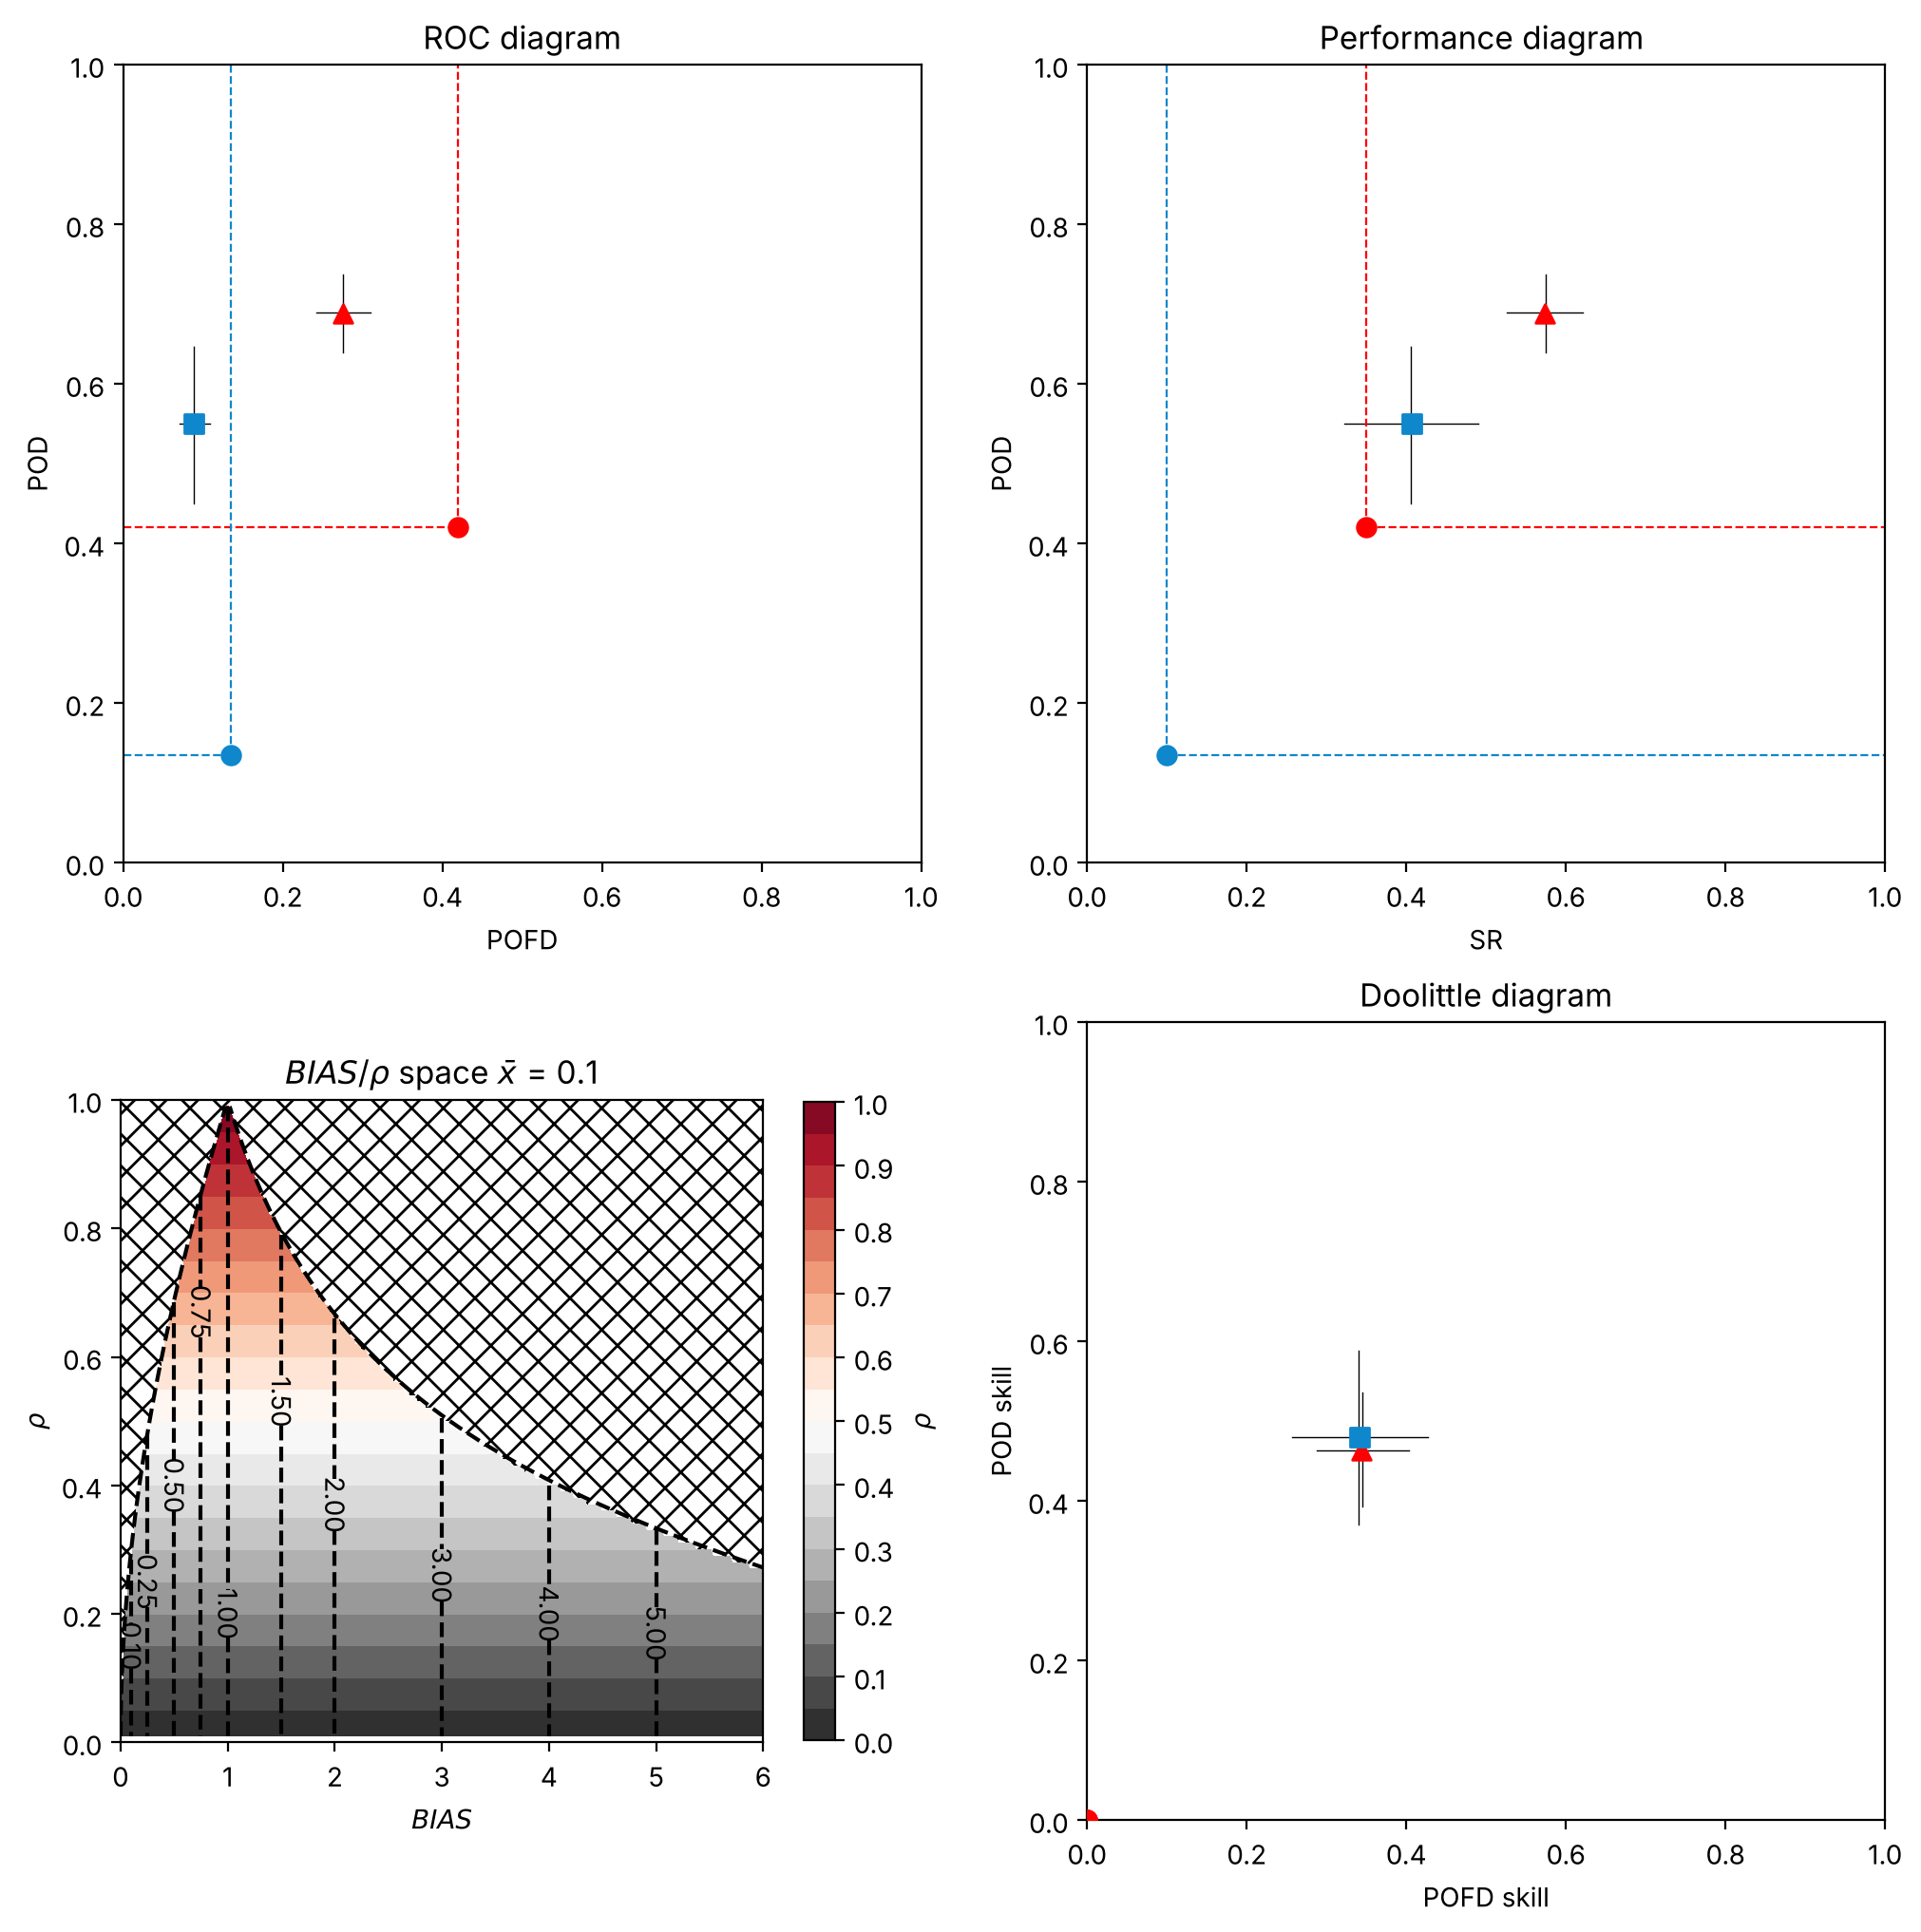

In [7]:
xbar=0.1

#xbar=307./1300.
colorlist=['xkcd:fire engine red','xkcd:violet','xkcd:water blue','xkcd:medium green','xkcd:dark purple','xkcd:burnt sienna','xkcd:orange','xkcd:lemon','xkcd:light red','xkcd:light indigo','xkcd:light cyan']

titl1=r'$\bar x$' + f' = {np.round(xbar,2)}'
#titl1=r'$\bar x$' + f' = {np.round(xbar,2)}'+r' $\rho$' + f' = {np.round(rho,2)}'

fig, axs = plt.subplots(2, 2,figsize=(12,12))
axs = axs.flat

bias1=np.arange(0.01,1.0/xbar,0.02)
rho1=np.arange(0.01,1.0,0.01)
bias_2d,rho_2d=np.meshgrid(bias1,rho1)

xx2,yy2=np.meshgrid(np.arange(0.01,1.0,0.01),np.arange(0.01,1.0,0.01))

pod1=np.arange(0.01,1.0,0.01)
sr1=np.arange(0.01,1.0,0.01)
sr2,pod2=np.meshgrid(sr1,pod1)
x_y=sr2/pod2
bias_prime=1./(xbar+x_y*(1.-xbar))

pofd1=np.arange(0.01,1.0,0.01)
pofd_roc,pod_roc=np.meshgrid(pofd1,pod1)
#y_x=pss2/css2
#c_2d=y_x*xbar*(1-xbar)
#c_2d[c_2d>0.25]=np.nan
#bias_pss_css=(0.5-np.sqrt(0.25-c_2d))/xbar
def srp2sr(x):
    return 0.10 + x*(1.-0.10)

def sr2srp(x):
    return (x-0.10)/(1.-0.10)

def podp2mr(x):
    return 0.10*(1.-x)

def mr2podp(x):
    return (0.10-x)/0.10


# pod/sr prime space
fbar_prime=bias_prime*xbar
aa_prime=xbar*(1.-fbar_prime)*pod2+fbar_prime*xbar
bb_prime=fbar_prime*(1.-xbar)*(1.-sr2)
cc_prime=xbar*(1.-fbar_prime)*(1.-pod2)
dd_prime=(1.-xbar)*(1.-fbar_prime)+xbar*(1.-fbar_prime)*pod2
rho_prime=np.sqrt(pod2*sr2)
mse_prime=bb_prime+cc_prime
bss_prime=1.-(bb_prime+cc_prime)/xbar/(1.-xbar)
csi_prime=aa_prime/(aa_prime+bb_prime+cc_prime)
q_prime=(aa_prime*dd_prime-bb_prime*cc_prime)/(aa_prime*dd_prime+bb_prime*cc_prime)
hss_prime=2.*(aa_prime*dd_prime-bb_prime*cc_prime)/((aa_prime+cc_prime)*(cc_prime+dd_prime)+(aa_prime+bb_prime)*(bb_prime+dd_prime))
d_prime_prime=norm.ppf(aa_prime/(aa_prime+cc_prime))-norm.ppf(bb_prime/(bb_prime+dd_prime))
#axs[3].contour(xx2,yy2,d_prime_prime,levels=[0.68],colors='k',linestyles='dashed')
#cs3=axs[3].contour(xx2,yy2,bias_prime,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
#axs[3].clabel(cs3, cs3.levels, inline=True, fontsize=10)
val_lvls=np.linspace(-1.,1.,21)
#sc3=axs[3].contourf(xx2,yy2,rho_prime,levels=np.linspace(0.,1.,21),cmap='RdGy_r',vmin=-0.02,vmax=1.02)
#plt.colorbar(sc3,orientation='vertical',shrink=0.8,location='right',label=r'$\phi$ (MCC)',ax=axs[3],ticks=np.linspace(0.,1.,11))
axs[3].set_aspect('equal')
axs[3].set_ylim(0.,1.)
axs[3].set_xlim(0.,1.)
axs[3].set_xlabel('POFD skill')
axs[3].set_ylabel('POD skill')
axs[3].set_title('Doolittle diagram')
#axs[3].set_title('skill-performance '+titl1)
#secax = axs[3].secondary_xaxis('top', functions=(srp2sr, sr2srp))
#secax.set_xlabel('alpha upper limit')
#secay = axs[3].secondary_yaxis('right', functions=(podp2mr, mr2podp))
#secay.set_ylabel('alpha lower limit')


# fbar/rho space
fbar=bias_2d*xbar
sx=np.sqrt(xbar*(1.-xbar))
sf=np.sqrt(fbar*(1.-fbar))
aa_2=rho_2d*sx*sf+fbar*xbar
bb_2=fbar*(1.-xbar)-rho_2d*sx*sf
cc_2=xbar*(1.-fbar)-rho_2d*sx*sf
dd_2=(1.-xbar)*(1.-fbar)+rho_2d*sx*sf
aa_2[(bb_2<0.)|(cc_2<0.)]=np.nan
dd_2[(bb_2<0.)|(cc_2<0.)]=np.nan
bb_2[(bb_2<0.)|(cc_2<0.)]=np.nan
cc_2[(bb_2<0.)|(cc_2<0.)]=np.nan

rho_2=np.sqrt((aa_2*dd_2-bb_2*cc_2)**2/(aa_2+bb_2)/(aa_2+cc_2)/(bb_2+dd_2)/(cc_2+dd_2))
odds_2=aa_2*dd_2/bb_2/cc_2
q_2=(odds_2-1.)/(odds_2+1.)
#q_2[q_2<-1.]=-1.
#q_2[q_2>1.]=1.
mse_2=bb_2+cc_2
bss_2=1.-(bb_2+cc_2)/xbar/(1.-xbar)
csi_2=aa_2/(aa_2+bb_2+cc_2)
hss_2=2.*(aa_2*dd_2-bb_2*cc_2)/((aa_2+cc_2)*(cc_2+dd_2)+(aa_2+bb_2)*(bb_2+dd_2))
bias_2=(aa_2+bb_2)/xbar
xodd=(1.-xbar)/xbar
test1=1./(xbar+(1.-xbar)*rho1*rho1)
test2=1./(xbar+(1.-xbar)/rho1/rho1)
axs[2].plot(test1,rho1,'k--',test2,rho1,'k--')
cs2=axs[2].contour(bias1,rho1,bias_2,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,3.,4.,5.],colors='k',linestyles='dashed')
axs[2].clabel(cs2, cs2.levels, inline=True, fontsize=10)
sc2=axs[2].contourf(bias1,rho1,rho_2,levels=np.linspace(0.,1.,21),cmap='RdGy_r',vmin=-0.02,vmax=1.02)
plt.colorbar(sc2,orientation='vertical',shrink=0.8,label=r'$\rho$',ax=axs[2],ticks=np.linspace(0.,1.,11))
axs[2].set_aspect(6.)
axs[2].set_ylim(0.,1.)
axs[2].set_xlim(0.,6.)
axs[2].set_xlabel(r'$BIAS$')
axs[2].set_ylabel(r'$\rho$')
axs[2].set_title(r'$BIAS$/$\rho$ space '+titl1)
# get data you will need to create a "background patch" to your plot
xmin, xmax = axs[2].get_xlim()
ymin, ymax = axs[2].get_ylim()
xy = (xmin,ymin+0.01)
width = xmax - xmin
height = ymax - ymin - 0.01
# create the patch and place it in the back of countourf (zorder!)
p = patches.Rectangle(xy, width, height, hatch='xx', fill=None, linewidth=0, zorder=-10)

axs[2].add_patch(p)

#POD SR space
aa_r=xbar*pod2
bb_r=xbar*(pod2/sr2-pod2)
cc_r=xbar*(1.-pod2)
dd_r=1.-xbar*(pod2/sr2+1.-pod2)
bias_roebber=pod2/sr2
pss_roebber=pod2-xbar*(pod2/sr2-pod2)
css_roebber=np.copy(aa_r)
css_roebber[sr2>xbar]=sr2[sr2>xbar]-(1.-pod2[sr2>xbar])*xbar/(1.-pod2[sr2>xbar]*xbar/sr2[sr2>xbar])
pss_roebber[sr2<=xbar]=np.nan
css_roebber[sr2<=xbar]=np.nan
rho_roebber=np.sqrt(pss_roebber*css_roebber)
q_roebber=(aa_r*dd_r-bb_r*cc_r)/(aa_r*dd_r+bb_r*cc_r)
mse_roebber=bb_r+cc_r
bss_roebber=1.-(bb_r+cc_r)/xbar/(1.-xbar)
csi_roebber=aa_r/(aa_r+bb_r+cc_r)
hss_roebber=2.*(aa_r*dd_r-bb_r*cc_r)/((aa_r+cc_r)*(cc_r+dd_r)+(aa_r+bb_r)*(bb_r+dd_r))
dprime_roebber=norm.ppf(pod2)-norm.ppf(bb_r/(bb_r+dd_r))
#bias_roebber[sr2<=xbar]=np.nan
rho_roebber[sr2<=xbar]=np.nan
mse_roebber[sr2<=xbar]=np.nan
bss_roebber[sr2<=xbar]=np.nan
hss_roebber[sr2<=xbar]=np.nan
#csi_roebber[sr2<=xbar]=np.nan
q_roebber[sr2<=xbar]=np.nan
aa_r[sr2<=xbar]=np.nan
bb_r[sr2<=xbar]=np.nan
cc_r[sr2<=xbar]=np.nan
dd_r[sr2<=xbar]=np.nan
xbar2=307./1300.
aa_r2=xbar2*pod2
bb_r2=xbar2*(pod2/sr2-pod2)
cc_r2=xbar2*(1.-pod2)
dd_r2=1.-xbar2*(pod2/sr2+1.-pod2)
dprime2_roebber=norm.ppf(pod2)-norm.ppf(bb_r2/(bb_r2+dd_r2))
#axs[1].contour(xx2,yy2,dprime_roebber,levels=[1.05],colors='k',linestyles='dashed')
#axs[1].contour(xx2,yy2,dprime2_roebber,levels=[0.68],colors='k',linestyles='dashed')
#axs[1].clabel(cs1, cs1.levels, inline=True, fontsize=10)
#sc1=axs[1].contourf(xx2,yy2,csi_roebber,levels=np.linspace(0.,1.,21),cmap='RdGy_r',vmin=-0.2,vmax=1.02)
#plt.colorbar(sc1,orientation='vertical',shrink=0.8,label=r'$CSI$',ax=axs[1],ticks=np.linspace(0.,1.,11))
#axs[1].plot([xbar,xbar],[0,0.44],color='k',linestyle='dotted')
axs[1].set_aspect('equal')
axs[1].set_ylim(0.,1.)
axs[1].set_xlim(0.,1.)
axs[1].set_xlabel('SR')
axs[1].set_ylabel('POD')
axs[1].set_title('Performance diagram ')
# get data you will need to create a "background patch" to your plot
xmin, xmax = axs[1].get_xlim()
ymin, ymax = axs[1].get_ylim()
xy = (xmin+0.01,ymin+0.01)
width = xmax - xmin - 0.02
height = ymax - ymin - 0.02
# create the patch and place it in the back of countourf (zorder!)
#p = patches.Rectangle(xy, width, height, hatch='..', linewidth=0,fill=None, zorder=-10)
#axs[1].add_patch(p)

#ROC space
aa_roc=xbar*pod_roc
bb_roc=(1-xbar)*pofd_roc
cc_roc=xbar*(1.-pod_roc)
dd_roc=(1-xbar)*(1.-pofd_roc)
pss_roc=pod_roc-pofd_roc
dprime_roc=norm.ppf(pod_roc)-norm.ppf(pofd_roc)
css_roc=aa_roc/(aa_roc+bb_roc)-cc_roc/(cc_roc+dd_roc)
bias_roc=pod_roc+(1.-xbar)*pofd_roc/xbar
rho_roc=np.sqrt(pss_roc*css_roc)
mse_roc=bb_roc+cc_roc
q_roc=(aa_roc*dd_roc-bb_roc*cc_roc)/(aa_roc*dd_roc+bb_roc*cc_roc)
bss_roc=1.-(bb_roc+cc_roc)/xbar/(1.-xbar)
csi_roc=aa_roc/(aa_roc+bb_roc+cc_roc)
hss_roc=2.*(aa_roc*dd_roc-bb_roc*cc_roc)/((aa_roc+cc_roc)*(cc_roc+dd_roc)+(aa_roc+bb_roc)*(bb_roc+dd_roc))
bias_roc[pod_roc<pofd_roc]=np.nan
rho_roc[pod_roc<pofd_roc]=np.nan
mse_roc[pod_roc<pofd_roc]=np.nan
bss_roc[pod_roc<pofd_roc]=np.nan
hss_roc[pod_roc<pofd_roc]=np.nan
csi_roc[pod_roc<pofd_roc]=np.nan
q_roc[pod_roc<pofd_roc]=np.nan
aa_roc[pod_roc<pofd_roc]=np.nan
bb_roc[pod_roc<pofd_roc]=np.nan
cc_roc[pod_roc<pofd_roc]=np.nan
dd_roc[pod_roc<pofd_roc]=np.nan
dprime_roc[pod_roc<pofd_roc]=np.nan
#cs0=axs[0].contour(pofd1,pod1,bias_roc,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
#axs[0].clabel(cs0, cs0.levels, inline=True, fontsize=10)
#sc0=axs[0].contourf(pofd1,pod1,rho_roc,levels=np.linspace(0.,1.,11),cmap='Reds',vmin=0.,vmax=1.)
d_lvls=np.linspace(0.,5.,21)
d_ticks=np.linspace(0.,5.,6)
#cs0=axs[0].contour(pofd1,pod1,dprime_roc,levels=[0.68],colors='k',linestyles='dashed')
#sc0=axs[0].contourf(pofd1,pod1,dprime_roc,levels=d_lvls,cmap='RdGy_r',vmin=-0.1,vmax=5.1)
#plt.colorbar(sc0,orientation='vertical',shrink=0.8,label=r'$d_{prime}$',ax=axs[0],ticks=d_ticks)
#axs[0].plot([0,1],[0,1],color='k',linestyle='dotted')
axs[0].set_aspect('equal')
axs[0].set_ylim(0.,1.)
axs[0].set_xlim(0.,1.)

axs[0].set_xlabel('POFD')
axs[0].set_ylabel('POD')
axs[0].set_title('ROC diagram')
# get data you will need to create a "background patch" to your plot
xmin, xmax = axs[0].get_xlim()
ymin, ymax = axs[0].get_ylim()
xy = (xmin+0.01,ymin+0.01)
width = xmax - xmin - 0.02
height = ymax - ymin - 0.02
# create the patch and place it in the back of countourf (zorder!)
p = patches.Rectangle(xy, width, height, hatch='..', linewidth=0,fill=None, zorder=-10)
#axs[0].add_patch(p)

dfa_a_sum=dfa.a.sum()
dfa_b_sum=dfa.b.sum()
dfa_c_sum=dfa.c.sum()
dfa_d_sum=dfa.d.sum()
dfb_a_sum=dfb.a.sum()
dfb_b_sum=dfb.b.sum()
dfb_c_sum=dfb.c.sum()
dfb_d_sum=dfb.d.sum()
dfa_n=dfa_a_sum+dfa_b_sum+dfa_c_sum+dfa_d_sum
dfb_n=dfb_a_sum+dfb_b_sum+dfb_c_sum+dfb_d_sum
#leg1=r' $\rho$' + f' = {np.round(rho_pts,2)}'
# df1['pofd']=df1['b']/(df1['b']+df1['d'])
# df1['bias']=df1['pod']/df1['sr']
# df1['css']=df1['pod']-df1['sr']
# df1['pss']=df1['pod']-df1['pofd']
# df1['phi']=np.sqrt(df1['pss']*df1['css'])
# df1['podp']=(df1['a']*df1['d']-df1['b']*df1['c'])/(df1['a']+df1['c'])/(df1['c']+df1['d'])
# df1['srp']=(df1['a']*df1['d']-df1['b']*df1['c'])/(df1['a']+df1['b'])/(df1['b']+df1['d'])

# df2['pofd']=df2['b']/(df2['b']+df2['d'])
# df2['bias']=df2['pod']/df2['sr']
# df2['css']=df2['pod']-df2['sr']
# df2['pss']=df2['pod']-df2['pofd']
# df2['phi']=np.sqrt(df2['pss']*df2['css'])
# df2['podp']=(df2['a']*df2['d']-df2['b']*df2['c'])/(df2['a']+df2['c'])/(df2['c']+df2['d'])
# df2['srp']=(df2['a']*df2['d']-df2['b']*df2['c'])/(df2['a']+df2['b'])/(df2['b']+df2['d'])

        # pod_thr[k]=aa/(aa+cc)
        # pofd_thr[k]=bb/(bb+dd)
        # sr_thr[k]=aa/(aa+bb)
        # mr_thr[k]=cc/(cc+dd)
        # bias_thr[k]=(aa+bb)/(aa+cc)
        # pss_thr[k]=pod_thr[k]-pofd_thr[k]
        # css_thr[k]=sr_thr[k]-mr_thr[k]
        # sf_sx_thr[k]=np.var(fcstbin,ddof=0)/np.var(obs_pts,ddof=0)
        # thr1[k]=thresh
        # ss1_thr[k]=2.*pss_thr[k]-pss_thr[k]/css_thr[k]-xbar_pts*(bias_thr[k]-1.)**2./(1-xbar_pts)
        # pod_p_thr[k]=(pod_thr[k]-bias_thr[k]*xbar_pts)/(1.-bias_thr[k]*xbar_pts)
        # sr_p_thr[k]=(sr_thr[k]-xbar_pts)/(1.-xbar_pts)

#axs[0].plot(df1['pofd'],df1['pod'],color=colorlist[0],label='rel 2',marker='x')
#axs[1].plot(df1['sr'],df1['pod'],color=colorlist[0],label='rel 2',marker='x')
#axs[2].plot(df1['bias'],df1['phi'],color=colorlist[0],label='rel 2',marker='x')
#axs[3].plot(df1['srp'],df1['podp'],color=colorlist[0],label='rel 2',marker='x')
axs[0].plot([np.percentile(pofda,2.5),np.percentile(pofda,97.5)],[np.percentile(poda,50.),np.percentile(poda,50.)],'k',lw=0.5)
axs[0].plot([np.percentile(pofda,50.),np.percentile(pofda,50.)],[np.percentile(poda,2.5),np.percentile(poda,97.5)],'k',lw=0.5)
axs[0].plot([np.percentile(pofdb,2.5),np.percentile(pofdb,97.5)],[np.percentile(podb,50.),np.percentile(podb,50.)],'k',lw=0.5)
axs[0].plot([np.percentile(pofdb,50.),np.percentile(pofdb,50.)],[np.percentile(podb,2.5),np.percentile(podb,97.5)],'k',lw=0.5)
#axs[0].plot([np.percentile(fbara,2.5),np.percentile(fbara,97.5)],[np.percentile(fbara,50.),np.percentile(fbara,50.)],'k',lw=0.5)
#axs[0].plot([np.percentile(fbara,50.),np.percentile(fbara,50.)],[np.percentile(fbara,2.5),np.percentile(fbara,97.5)],'k',lw=0.5)
#axs[0].plot([np.percentile(fbarb,2.5),np.percentile(fbarb,97.5)],[np.percentile(fbarb,50.),np.percentile(fbarb,50.)],'k',lw=0.5)
#axs[0].plot([np.percentile(fbarb,50.),np.percentile(fbarb,50.)],[np.percentile(fbarb,2.5),np.percentile(fbarb,97.5)],'k',lw=0.5)
axs[1].plot([np.percentile(sra,2.5),np.percentile(sra,97.5)],[np.percentile(poda,50.),np.percentile(poda,50.)],'k',lw=0.5)
axs[1].plot([np.percentile(sra,50.),np.percentile(sra,50.)],[np.percentile(poda,2.5),np.percentile(poda,97.5)],'k',lw=0.5)
axs[1].plot([np.percentile(srb,2.5),np.percentile(srb,97.5)],[np.percentile(podb,50.),np.percentile(podb,50.)],'k',lw=0.5)
axs[1].plot([np.percentile(srb,50.),np.percentile(srb,50.)],[np.percentile(podb,2.5),np.percentile(podb,97.5)],'k',lw=0.5)
#axs[1].plot([np.percentile(xbara,2.5),np.percentile(xbara,97.5)],[np.percentile(fbara,50.),np.percentile(fbara,50.)],'k',lw=0.5)
#axs[1].plot([np.percentile(xbara,50.),np.percentile(xbara,50.)],[np.percentile(fbara,2.5),np.percentile(fbara,97.5)],'k',lw=0.5)
#axs[1].plot([np.percentile(xbarb,2.5),np.percentile(xbarb,97.5)],[np.percentile(fbarb,50.),np.percentile(fbarb,50.)],'k',lw=0.5)
#axs[1].plot([np.percentile(xbarb,50.),np.percentile(xbarb,50.)],[np.percentile(fbarb,2.5),np.percentile(fbarb,97.5)],'k',lw=0.5)
axs[3].plot([np.percentile(sr_skilla,2.5),np.percentile(sr_skilla,97.5)],[np.percentile(pod_skilla,50.),np.percentile(pod_skilla,50.)],'k',lw=0.5)
axs[3].plot([np.percentile(sr_skilla,50.),np.percentile(sr_skilla,50.)],[np.percentile(pod_skilla,2.5),np.percentile(pod_skilla,97.5)],'k',lw=0.5)
axs[3].plot([np.percentile(sr_skillb,2.5),np.percentile(sr_skillb,97.5)],[np.percentile(pod_skillb,50.),np.percentile(pod_skillb,50.)],'k',lw=0.5)
axs[3].plot([np.percentile(sr_skillb,50.),np.percentile(sr_skillb,50.)],[np.percentile(pod_skillb,2.5),np.percentile(pod_skillb,97.5)],'k',lw=0.5)

axs[0].plot([0,(dfa_a_sum+dfa_b_sum)/(dfa_n)],[(dfa_a_sum+dfa_b_sum)/(dfa_n),(dfa_a_sum+dfa_b_sum)/(dfa_n)],color=colorlist[0],linestyle='dashed',lw=0.8)
axs[0].plot([(dfa_a_sum+dfa_b_sum)/(dfa_n),(dfa_a_sum+dfa_b_sum)/(dfa_n)],[(dfa_a_sum+dfa_b_sum)/(dfa_n),1],color=colorlist[0],linestyle='dashed',lw=0.8)
axs[0].plot([0,(dfb_a_sum+dfb_b_sum)/(dfb_n)],[(dfb_a_sum+dfb_b_sum)/(dfb_n),(dfb_a_sum+dfb_b_sum)/(dfb_n)],color=colorlist[2],linestyle='dashed',lw=0.8)
axs[0].plot([(dfb_a_sum+dfb_b_sum)/(dfb_n),(dfb_a_sum+dfb_b_sum)/(dfb_n)],[(dfb_a_sum+dfb_b_sum)/(dfb_n),1],color=colorlist[2],linestyle='dashed',lw=0.8)

axs[1].plot([(dfa_a_sum+dfa_c_sum)/(dfa_n),1],[(dfa_a_sum+dfa_b_sum)/(dfa_n),(dfa_a_sum+dfa_b_sum)/(dfa_n)],color=colorlist[0],linestyle='dashed',lw=0.8)
axs[1].plot([(dfa_a_sum+dfa_c_sum)/(dfa_n),(dfa_a_sum+dfa_c_sum)/(dfa_n)],[(dfa_a_sum+dfa_b_sum)/(dfa_n),1],color=colorlist[0],linestyle='dashed',lw=0.8)
axs[1].plot([(dfb_a_sum+dfb_c_sum)/(dfb_n),1],[(dfb_a_sum+dfb_b_sum)/(dfb_n),(dfb_a_sum+dfb_b_sum)/(dfb_n)],color=colorlist[2],linestyle='dashed',lw=0.8)
axs[1].plot([(dfb_a_sum+dfb_c_sum)/(dfb_n),(dfb_a_sum+dfb_c_sum)/(dfb_n)],[(dfb_a_sum+dfb_b_sum)/(dfb_n),1],color=colorlist[2],linestyle='dashed',lw=0.8)
#dfa['fbar']=dfa.a+dfa.b
#dfa['xbar']=dfa.a+dfa.c
#dfa['POD']=dfa.a/(dfa.a+dfa.c)
#dfa['SR']=dfa.a/(dfa.a+dfa.b)
#dfa['rand']=(dfa.a+dfa.c)*(dfa.a+dfa.b)
#dfa['PODskill']=(dfa.POD-dfa.fbar)/(1.-dfa.fbar)
#dfa['SRskill']=(dfa.SR-dfa.xbar)/(1.-dfa.xbar)
#(a*d-b*c)/(a+c)/(c+d)
axs[0].scatter(dfa_b_sum/(dfa_b_sum+dfa_d_sum),dfa_a_sum/(dfa_a_sum+dfa_c_sum),color=colorlist[0],label='test',s=50.,marker='^',zorder=3)
axs[1].scatter(dfa_a_sum/(dfa_a_sum+dfa_b_sum),dfa_a_sum/(dfa_a_sum+dfa_c_sum),color=colorlist[0],label='test',s=50.,marker='^',zorder=3)
#axs[2].scatter(dfa['bias'],dfa['phi'],color=colorlist[0],label='test',marker='.')
axs[3].scatter((dfa_a_sum*dfa_d_sum-dfa_b_sum*dfa_c_sum)/(dfa_a_sum+dfa_b_sum)/(dfa_b_sum+dfa_d_sum),(dfa_a_sum*dfa_d_sum-dfa_b_sum*dfa_c_sum)/(dfa_a_sum+dfa_c_sum)/(dfa_c_sum+dfa_d_sum),color=colorlist[0],label='test',s=50.,marker='^',zorder=3)

axs[0].scatter((dfa_a_sum+dfa_b_sum)/(dfa_n),(dfa_a_sum+dfa_b_sum)/(dfa_n) ,color=colorlist[0],s=50.,label='test',marker='o')
axs[1].scatter((dfa_a_sum+dfa_c_sum)/(dfa_n),(dfa_a_sum+dfa_b_sum)/(dfa_n) ,color=colorlist[0],s=50., label='test',marker='o')

axs[0].scatter(dfb_b_sum/(dfb_b_sum+dfb_d_sum),dfb_a_sum/(dfb_a_sum+dfb_c_sum),color=colorlist[2],label='test',s=50.,marker='s',zorder=3)
axs[1].scatter(dfb_a_sum/(dfb_a_sum+dfb_b_sum),dfb_a_sum/(dfb_a_sum+dfb_c_sum),color=colorlist[2],label='test',s=50.,marker='s',zorder=3)
#axs[2].scatter(dfb['bias'],dfa['phi'],color=colorlist[0],label='test',marker='.')
axs[3].scatter((dfb_a_sum*dfb_d_sum-dfb_b_sum*dfb_c_sum)/(dfb_a_sum+dfb_b_sum)/(dfb_b_sum+dfb_d_sum),(dfb_a_sum*dfb_d_sum-dfb_b_sum*dfb_c_sum)/(dfb_a_sum+dfb_c_sum)/(dfb_c_sum+dfb_d_sum),color=colorlist[2],label='test',s=50.,marker='s',zorder=3)
axs[0].scatter((dfb_a_sum+dfb_b_sum)/(dfb_n),(dfb_a_sum+dfb_b_sum)/(dfb_n) ,color=colorlist[2],s=50.,label='test',marker='o')
axs[1].scatter((dfb_a_sum+dfb_c_sum)/(dfb_n),(dfb_a_sum+dfb_b_sum)/(dfb_n) ,color=colorlist[2],s=50., label='test',marker='o')

#axs[2].scatter(df1['bias'],df1['phi'],color=colorlist[0],s=10.,label='test',marker='x')
axs[3].scatter(df1['zero'],df1['zero'],color=colorlist[0],s=50.,label='test',marker='o',zorder=3)
#axs[0].legend()
#axs[1].legend()
#axs[2].legend()
#axs[3].legend()

In [8]:
# [added] save Fig. 1 (top row) and Fig. 2 (bottom-right panel) as separate files
from matplotlib.transforms import Bbox
def save_axes(fig, axes_list, fname, pad=0.1):
    bb = Bbox.union([ax.get_tightbbox() for ax in axes_list])
    fig.savefig(fname, bbox_inches=bb.transformed(fig.dpi_scale_trans.inverted()).padded(pad))

save_axes(fig, [axs[0], axs[1]], 'figures/fig01.pdf')
save_axes(fig, [axs[3]], 'figures/fig02.pdf')

## Fig. 3, top row: x̄ = 0.1 (original cell 213)

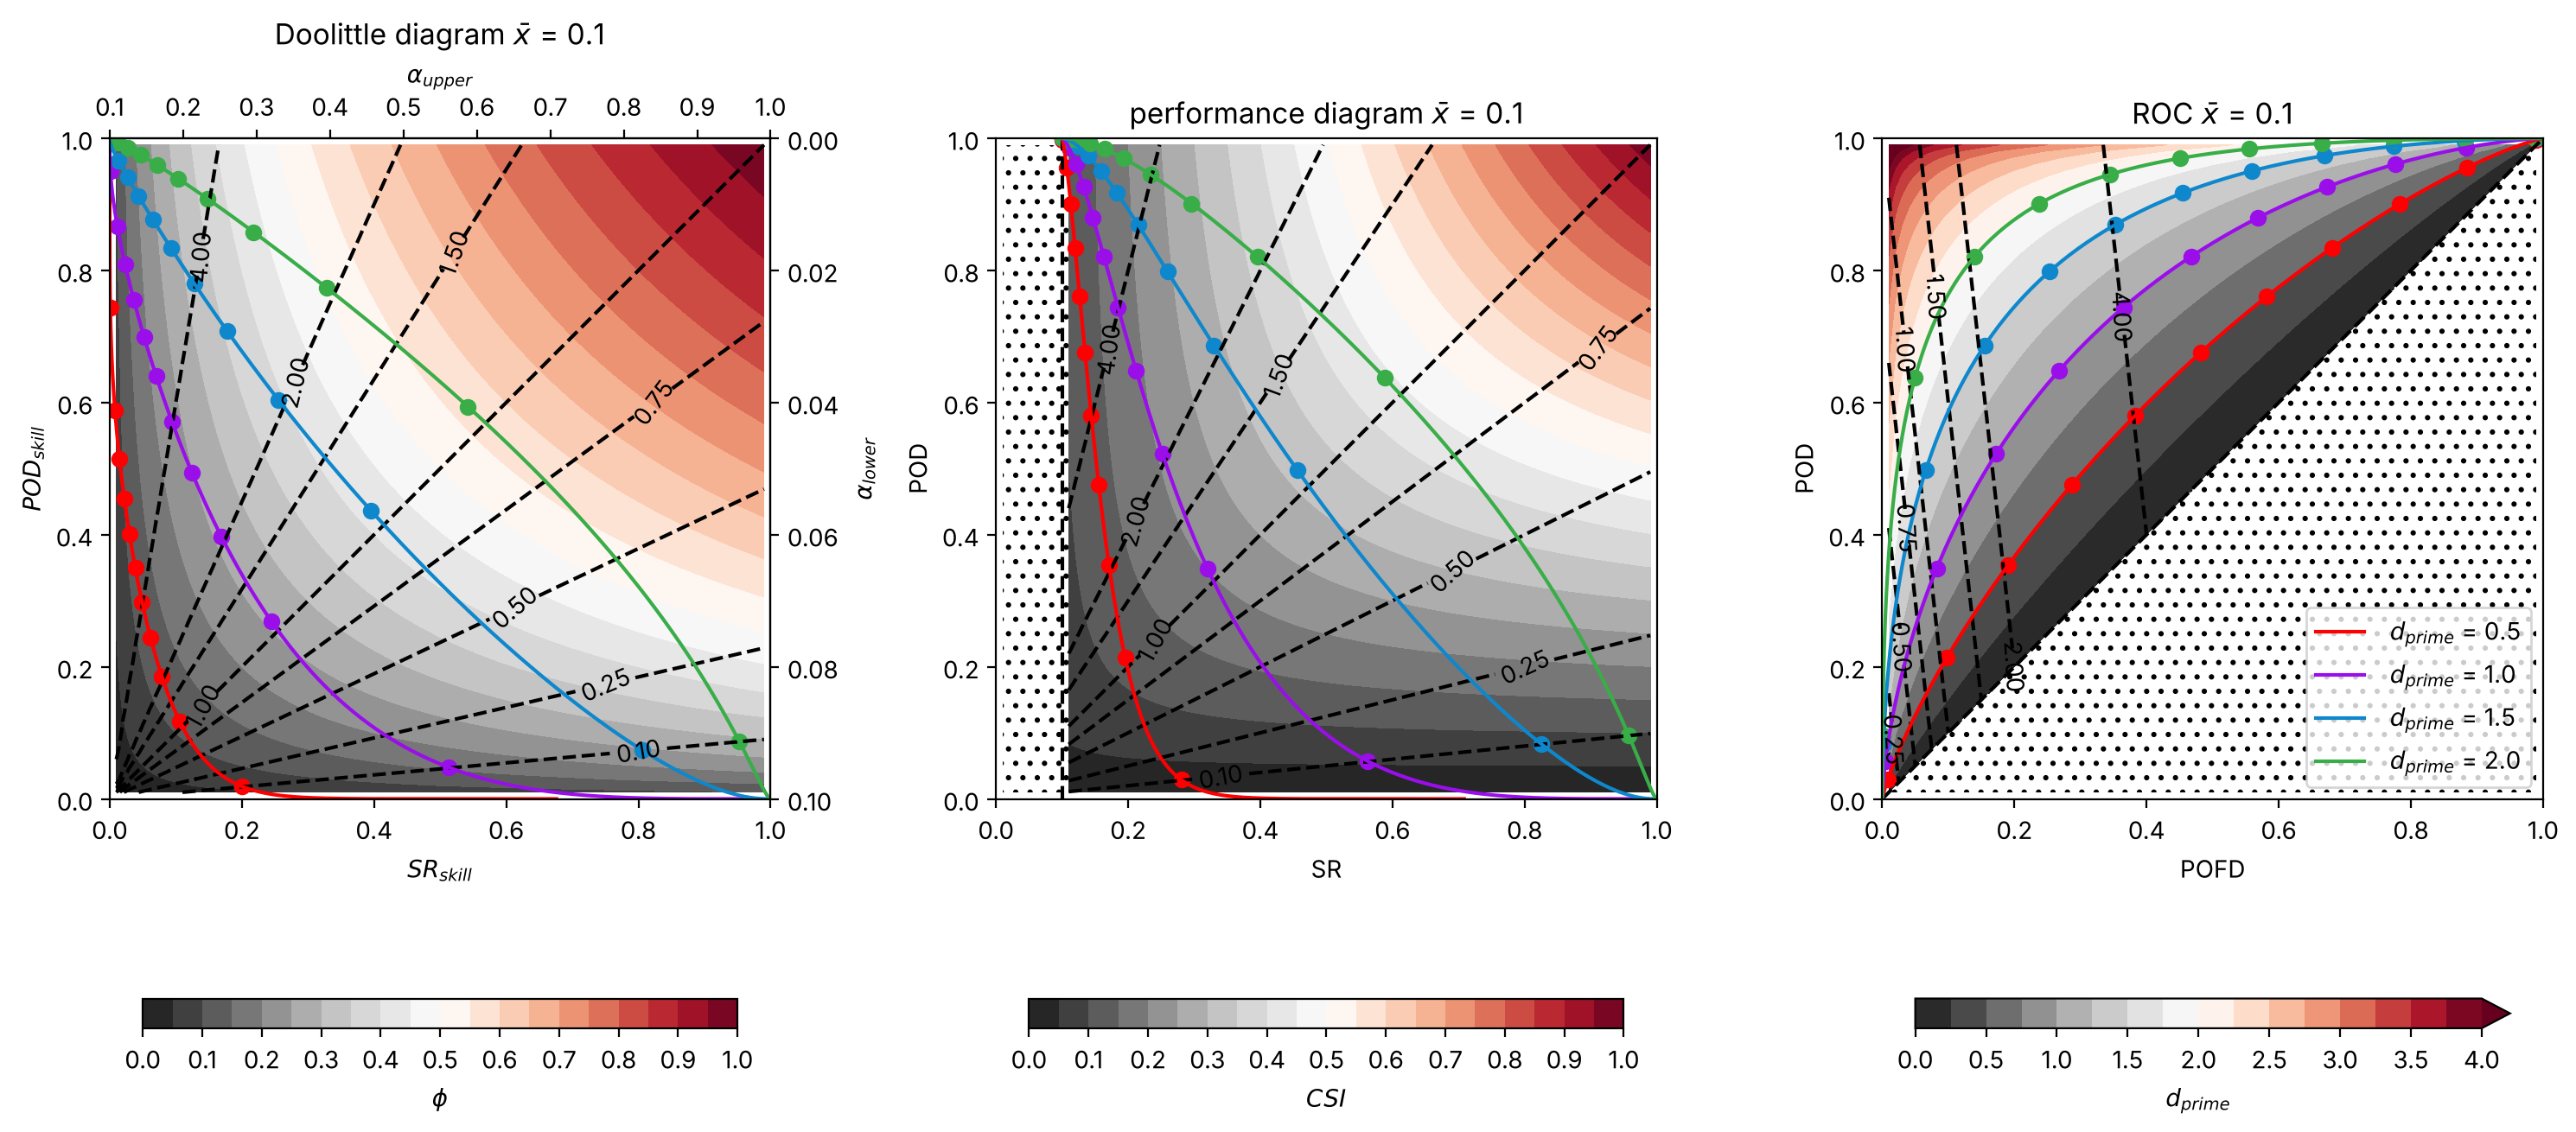

In [9]:
def pod(a,b,c,d):
    return a/(a+c)
    
def sr(a,b,c,d):
    return a/(a+b)    

def pofd(a,b,c,d):
    return b/(b+d)
    
def mr(a,b,c,d):
    return c/(c+d)

def csi(a,b,c,d):
    return a/(a+b+c)

def tversky(a,b,c,d,gamma):
    return a/(a+gamma*b+(1.-gamma)*c)
    
def pss(a,b,c,d):
    return (a*d-b*c)/(a+c)/(b+d)

def css(a,b,c,d):
    return (a*d-b*c)/(a+b)/(c+d)

def qyule(a,b,c,d):
    return (a*d-b*c)/(a*d+b*c)

def mse(a,b,c,d):
    return b+c
    
def srskill(a,b,c,d):
    return (a*d-b*c)/(a+b)/(b+d)
    
def podskill(a,b,c,d):
    return (a*d-b*c)/(a+c)/(c+d)
    
def deelia(a,b,c,d):
    return np.log(b/(a+b))/np.log(a/(a+c))

def hss(a,b,c,d):
    return 2.*(a*d-b*c)/((a+c)*(c+d)+(a+b)*(b+d))

def kappa(a,b,c,d,w):
    return (a*d-b*c)/((1.-w)*(a+c)*(c+d)+w*(a+b)*(b+d))

def dprime(a,b,c,d):
    return norm.ppf(a/(a+c))-norm.ppf(b/(b+d))

def phi(a,b,c,d):
    return (a*d-b*c)/np.sqrt((a+c)*(c+d)*(a+b)*(b+d))

def relvalue(a,b,c,d,alpha,xbar):
    if alpha>xbar:
        relval=((1.-alpha)*a-alpha*b)/(1.-alpha)/xbar
    else:
        relval=(alpha*d-(1.-alpha)*c)/alpha/(1.-xbar)
    return relval



#divnorm = colors.TwoSlopeNorm(vmin=0., vcenter=1, vmax=10.)
#divnorm =colors.LogNorm(vmin=10.**(-1.5), vmax=10.**(2.75))

# loop over base rates
colorlist=['xkcd:fire engine red','xkcd:violet','xkcd:water blue','xkcd:medium green','xkcd:dark purple','xkcd:burnt sienna','xkcd:orange','xkcd:lemon','xkcd:light red','xkcd:light indigo','xkcd:light cyan']

# maybe turn this into a random sample from normal distributions

xbar=0.1
titl1=r'$\bar x$' + f' = {np.round(xbar,2)}'
zscore1=np.linspace(-6.,6.,1001)
dprime1=np.linspace(0.001,5.0,501)
zs_2d,dprime_2d=np.meshgrid(zscore1,dprime1)
a_xbar=norm.cdf(zs_2d,loc=-0.5*dprime_2d,scale=1.)
b_1mxbar=norm.cdf(zs_2d,loc=0.5*dprime_2d,scale=1.)

xodd=(1.-xbar)/xbar
aa=a_xbar*xbar
bb=b_1mxbar*(1.-xbar)
cc=(1.-a_xbar)*xbar
dd=(1.-b_1mxbar)*(1.-xbar)
podskill1=(aa*dd-bb*cc)/(aa+cc)/(cc+dd)
srskill1=(aa*dd-bb*cc)/(aa+bb)/(bb+dd)
#grid_plot0=np.sqrt(podskill1*srskill1)

grid_plot0=csi(aa,bb,cc,dd)

# grid_plot1=pss(aa,bb,cc,dd)
# label1=r'$PSS$'
# grid_plot2=relvalue(aa,bb,cc,dd,xbar*0.5,xbar)
# label2=r"$V_{rel}[\alpha=0.5*\bar x]$"
# grid_plot3=relvalue(aa,bb,cc,dd,xbar*2.0,xbar)
# label3=r"$V_{rel}[\alpha=2.0*\bar x]$"

grid_plot1=pod(aa,bb,cc,dd)
grid_plot2=phi(aa,bb,cc,dd)
grid_sr=sr(aa,bb,cc,dd)

grid_bias=a_xbar+xodd*b_1mxbar
grid_pod=aa/(aa+cc)
grid_far=bb/(aa+bb)
grid_pofd=bb/(bb+dd)
grid_bias_odds=np.arctan2(podskill1,srskill1)*180./np.pi
n=1
titl1=r'$\bar x$' + f' = {np.round(xbar,2)}'

xx2,yy2=np.meshgrid(np.arange(0.01,1.0,0.01),np.arange(0.01,1.0,0.01))

#2x2 table in Doolittle pod/sr skill space
pod1=np.arange(0.01,1.0,0.01)
sr1=np.arange(0.01,1.0,0.01)
sr2,pod2=np.meshgrid(sr1,pod1)
x_y=sr2/pod2
bias_prime=1./(xbar+x_y*(1.-xbar))
fbar_prime=bias_prime*xbar
aa_prime=xbar*(1.-fbar_prime)*pod2+fbar_prime*xbar
bb_prime=fbar_prime*(1.-xbar)*(1.-sr2)
cc_prime=xbar*(1.-fbar_prime)*(1.-pod2)
dd_prime=(1.-xbar)*(1.-fbar_prime)+xbar*(1.-fbar_prime)*pod2


#2x2 table in Roebber POD SR space
aa_r=xbar*pod2
bb_r=xbar*(pod2/sr2-pod2)
cc_r=xbar*(1.-pod2)
dd_r=1.-xbar*(pod2/sr2+1.-pod2)
bias_roebber=pod2/sr2
bias_roebber[sr2<=xbar]=np.nan
aa_r[sr2<=xbar]=np.nan
bb_r[sr2<=xbar]=np.nan
cc_r[sr2<=xbar]=np.nan
dd_r[sr2<=xbar]=np.nan

#2x2 table in ROC POD POFD space
pofd1=np.arange(0.01,1.0,0.01)
pofd_roc,pod_roc=np.meshgrid(pofd1,pod1)
aa_roc=xbar*pod_roc
bb_roc=(1-xbar)*pofd_roc
cc_roc=xbar*(1.-pod_roc)
dd_roc=(1-xbar)*(1.-pofd_roc)
aa_roc[pod_roc<pofd_roc]=np.nan
bb_roc[pod_roc<pofd_roc]=np.nan
cc_roc[pod_roc<pofd_roc]=np.nan
dd_roc[pod_roc<pofd_roc]=np.nan
bias_roc=pod_roc+(1.-xbar)*pofd_roc/xbar
bias_roc[pod_roc<pofd_roc]=np.nan


fig, axs = plt.subplots(1, 3,figsize=(15,8))
axs = axs.flat

#figfile='/users/baldwin/plots/CSI' + f'{n}' + '.png'

# if j==1:
#     figfile='/users/baldwin/plots/PHI' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$\phi$"
#     extend1='neither'
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=phi(aa_prime,bb_prime,cc_prime,dd_prime)
#     fill_roebber=phi(aa_r,bb_r,cc_r,dd_r)
#     fill_roc=phi(aa_roc,bb_roc,cc_roc,dd_roc)
# if j==2:
#     figfile='/users/baldwin/plots/Dprime' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$D_{prime}$"
#     extend1='both'
#     d_lvls=np.linspace(0.,4.,21)
#     d_ticks=np.linspace(0.,4.,5)
#     fill_prime=dprime(aa_prime,bb_prime,cc_prime,dd_prime)
#     fill_roebber=dprime(aa_r,bb_r,cc_r,dd_r)
#     fill_roc=dprime(aa_roc,bb_roc,cc_roc,dd_roc)
# if j==3:
#     figfile='/users/baldwin/plots/Tversky0_2' + f'{n}' + '.png'
#     gamma=0.2
#     cmap1='RdGy_r'
#     label1=r"$Tversky[\gamma=0.2]$"
#     extend1='neither'
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=tversky(aa_prime,bb_prime,cc_prime,dd_prime,gamma)
#     fill_roebber=tversky(aa_r,bb_r,cc_r,dd_r,gamma)
#     fill_roc=tversky(aa_roc,bb_roc,cc_roc,dd_roc,gamma)
# if j==4:
#     figfile='/users/baldwin/plots/kappa0_2' + f'{n}' + '.png'
#     w=0.2
#     cmap1='RdGy_r'
#     label1=r"$\kappa[w=0.2]$"
#     extend1='neither'
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=kappa(aa_prime,bb_prime,cc_prime,dd_prime,w)
#     fill_roebber=kappa(aa_r,bb_r,cc_r,dd_r,w)
#     fill_roc=kappa(aa_roc,bb_roc,cc_roc,dd_roc,w)
# if j==5:
#     figfile='/users/baldwin/plots/Relval_low' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$V_{rel}[\alpha=0.5*\bar x]$"
#     extend1='min'
#     alpha=0.5*xbar
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=relvalue(aa_prime,bb_prime,cc_prime,dd_prime,alpha,xbar)
#     fill_roebber=relvalue(aa_r,bb_r,cc_r,dd_r,alpha,xbar)
#     fill_roc=relvalue(aa_roc,bb_roc,cc_roc,dd_roc,alpha,xbar)
# if j==6:
#     figfile='/users/baldwin/plots/Relval_high' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$V_{rel}[\alpha=2*\bar x]$"
#     extend1='min'
#     alpha=2.0*xbar
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=relvalue(aa_prime,bb_prime,cc_prime,dd_prime,alpha,xbar)
#     fill_roebber=relvalue(aa_r,bb_r,cc_r,dd_r,alpha,xbar)
#     fill_roc=relvalue(aa_roc,bb_roc,cc_roc,dd_roc,alpha,xbar)

#plot diagrams with bias and score backgrounds
# Doolittle
cmap1='RdGy_r'
label1=r"$\phi$"
extend1='neither'
d_lvls=np.linspace(0.,1.,21)
d_ticks=np.linspace(0.,1.,11)
fill_prime=phi(aa_prime,bb_prime,cc_prime,dd_prime)

cs0=axs[0].contour(xx2,yy2,bias_prime,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
axs[0].clabel(cs0, cs0.levels, inline=True, fontsize=10)
sc0=axs[0].contourf(xx2,yy2,fill_prime,levels=d_lvls,cmap=cmap1,extend=extend1)
plt.colorbar(sc0,orientation='horizontal',shrink=0.9,label=label1,ax=axs[0],ticks=d_ticks)
axs[0].set_aspect('equal')
axs[0].set_ylim(0.,1.)
axs[0].set_xlim(0.,1.)
axs[0].set_xlabel(r'$SR_{skill}$')
axs[0].set_ylabel(r'$POD_{skill}$')
axs[0].set_title('Doolittle diagram '+titl1)
if n==0:
    secax = axs[0].secondary_xaxis('top', functions=(srp2sr01, sr2srp01))
    secay = axs[0].secondary_yaxis('right', functions=(podp2mr01, mr2podp01))
if n==1:
    secax = axs[0].secondary_xaxis('top', functions=(srp2sr10, sr2srp10))
    secay = axs[0].secondary_yaxis('right', functions=(podp2mr10, mr2podp10))
if n==2:
    secax = axs[0].secondary_xaxis('top', functions=(srp2sr25, sr2srp25))
    secay = axs[0].secondary_yaxis('right', functions=(podp2mr25, mr2podp25))
if n==3:
    secax = axs[0].secondary_xaxis('top', functions=(srp2sr33, sr2srp33))
    secay = axs[0].secondary_yaxis('right', functions=(podp2mr33, mr2podp33))
secax.set_xlabel(r'$\alpha_{upper}$')
secay.set_ylabel(r'$\alpha_{lower}$')

#Roebber
cmap1='RdGy_r'
label1=r"$CSI$"
extend1='neither'
d_lvls=np.linspace(0.,1.,21)
d_ticks=np.linspace(0.,1.,11)
fill_roebber=csi(aa_r,bb_r,cc_r,dd_r)

cs1=axs[1].contour(xx2,yy2,bias_roebber,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
axs[1].clabel(cs1, cs1.levels, inline=True, fontsize=10)
sc1=axs[1].contourf(pofd1,pod1,fill_roebber,levels=d_lvls,cmap=cmap1,extend=extend1)
plt.colorbar(sc1,orientation='horizontal',shrink=0.9,label=label1,ax=axs[1],ticks=d_ticks)
axs[1].plot([xbar,xbar],[0,1],color='k',linestyle='dashed')
axs[1].set_aspect('equal')
axs[1].set_ylim(0.,1.)
axs[1].set_xlim(0.,1.)
axs[1].set_xlabel('SR')
axs[1].set_ylabel('POD')
axs[1].set_title('performance diagram '+titl1)
# "no skill" patch
xmin, xmax = axs[1].get_xlim()
ymin, ymax = axs[1].get_ylim()
xy = (xmin+0.01,ymin+0.01)
width = xmax - xmin - 0.02
height = ymax - ymin - 0.02
p = patches.Rectangle(xy, width, height, hatch='..', linewidth=0,fill=None, zorder=-10)
axs[1].add_patch(p)

#ROC
cmap1='RdGy_r'
label1=r"$d_{prime}$"
extend1='max'
d_lvls=np.linspace(0.,4.,17)
d_ticks=np.linspace(0.,4.,9)
fill_roc=dprime(aa_roc,bb_roc,cc_roc,dd_roc)

cs2=axs[2].contour(pofd1,pod1,bias_roc,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
axs[2].clabel(cs2, cs2.levels, inline=True, fontsize=10)
sc2=axs[2].contourf(pofd1,pod1,fill_roc,levels=d_lvls,cmap=cmap1,extend=extend1)
plt.colorbar(sc2,orientation='horizontal',shrink=0.9,label=label1,ax=axs[2],ticks=d_ticks)
axs[2].plot([0,1],[0,1],color='k',linestyle='dashed',zorder=2)
axs[2].set_aspect('equal')
axs[2].set_ylim(0.,1.)
axs[2].set_xlim(0.,1.)
axs[2].set_xlabel('POFD')
axs[2].set_ylabel('POD')
axs[2].set_title('ROC '+titl1)
# "no skill" patch
xmin, xmax = axs[0].get_xlim()
ymin, ymax = axs[0].get_ylim()
xy = (xmin+0.01,ymin+0.01)
width = xmax - xmin - 0.02
height = ymax - ymin - 0.02
p = patches.Rectangle(xy, width, height, hatch='..', linewidth=0,fill=None, zorder=-10)
axs[2].add_patch(p)

# loop over fcst/obs examples in dataframe
# plot verification curves in all three diagrams
for i in np.arange(4):
    j=(i+1)*50
    leg1=r' $d_{prime}$' + f' = {np.round(dprime1[j],1)}'
    axs[0].plot(srskill1[j,:],podskill1[j,:],color=colorlist[i],label=leg1)
    axs[1].plot(grid_sr[j,:],grid_pod[j,:],color=colorlist[i],label=leg1)
    axs[2].plot(grid_pofd[j,:],grid_pod[j,:],color=colorlist[i],label=leg1)
    for thr in np.linspace(0.01,0.99,11):
        axs[0].scatter(srskill1[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],podskill1[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],c=colorlist[i])
        axs[1].scatter(grid_sr[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],grid_pod[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],c=colorlist[i])
        axs[2].scatter(grid_pofd[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],grid_pod[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],c=colorlist[i])
#     dfi=df_plot[df_plot.color==i]

#     axs[0].plot(dfi.sr_skill,dfi.pod_skill,color=colorlist[i],label=leg1)
#     axs[1].plot(dfi.sr,dfi.pod,color=colorlist[i],label=leg1)
#     axs[2].plot(dfi.pofd,dfi.pod,color=colorlist[i],label=leg1)
#     axs[0].scatter(x=dfi.sr_skill,y=dfi.pod_skill,c=dfi.thr,cmap='Greys',vmin=-0.1,vmax=1.2)
#     axs[1].scatter(x=dfi.sr,y=dfi.pod,c=dfi.thr,cmap='Greys',vmin=-0.1,vmax=1.2)
#     axs[2].scatter(x=dfi.pofd,y=dfi.pod,c=dfi.thr,cmap='Greys',vmin=-0.1,vmax=1.2)

axs[2].legend()
plt.tight_layout()
#plt.savefig(figfile)
#plt.close()

In [10]:
# [added] save Fig. 3 top row
fig.savefig('figures/fig03a.pdf', bbox_inches='tight')

## Fig. 3, bottom row: x̄ = 0.33 (original cell 219)

/tmp/ipykernel_247/1350579819.py:323: RuntimeWarning: invalid value encountered in scalar divide
  mr_thr[k]=cc/(cc+dd)
/tmp/ipykernel_247/1350579819.py:330: RuntimeWarning: invalid value encountered in scalar divide
  pod_p_thr[k]=(pod_thr[k]-bias_thr[k]*xbar_pts)/(1.-bias_thr[k]*xbar_pts)


0.9935454545454545 0.3338730372090181 0.9763432835820895 0.98202 0.6410152694913519 0.0057806525507732905
0.9970909090909091 0.33821579450491845 0.9609402985074627 0.97287 0.8927721743792532 0.012262379858087223
0.9986363636363637 0.34538956547257216 0.9322238805970149 0.95414 0.9702652341117238 0.022969500705331557
0.9995757575757576 0.35499736329491277 0.8945223880597015 0.92919 0.9940087215895715 0.03730949745509367


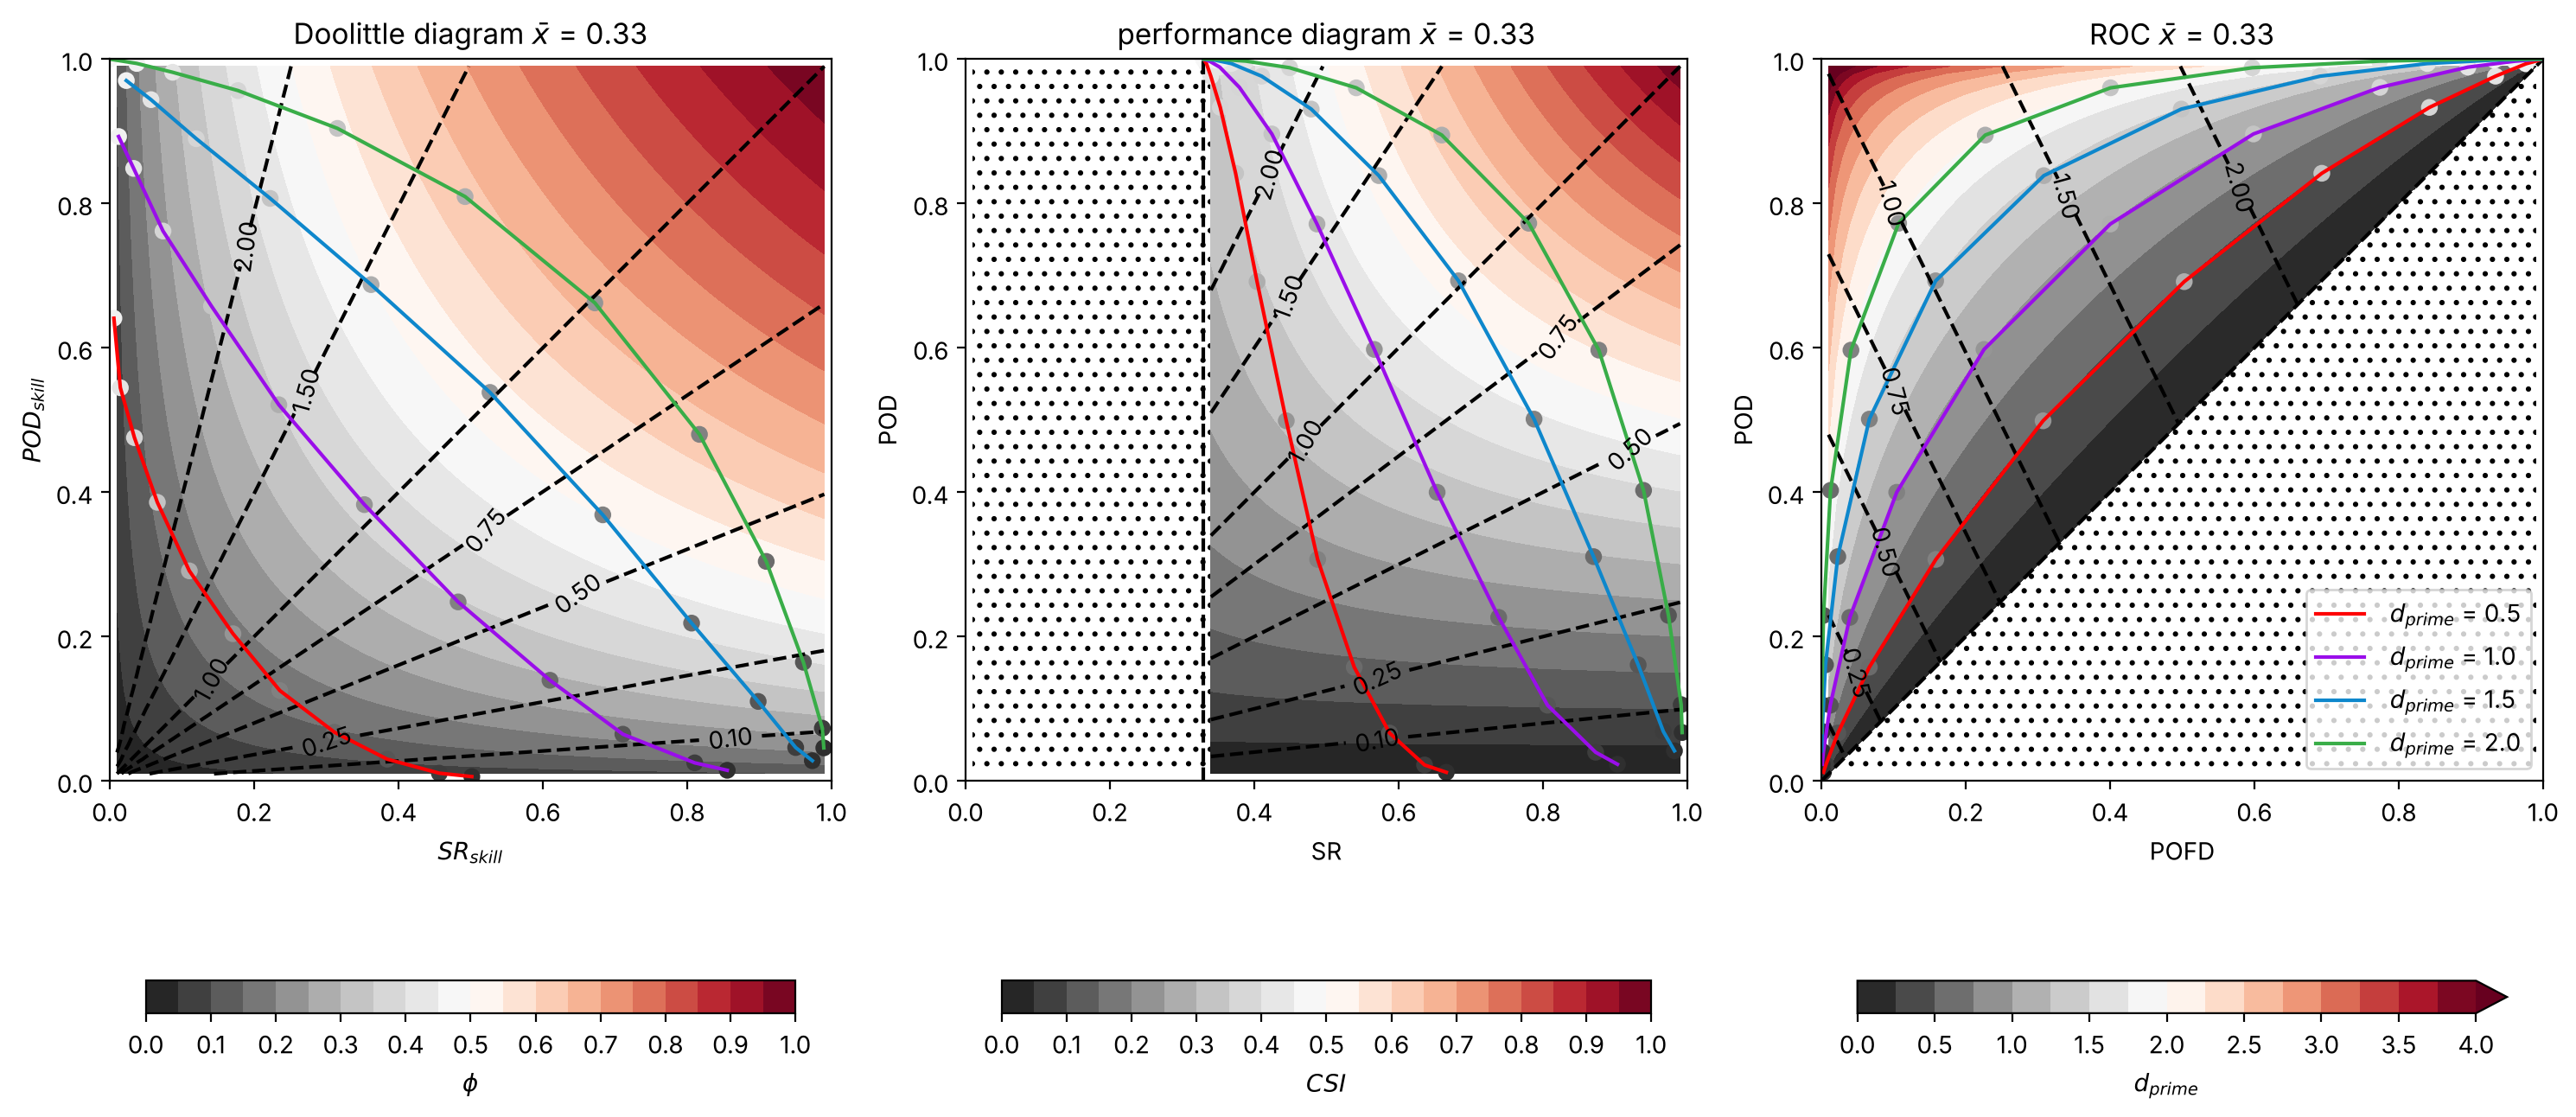

In [11]:
def pod(a,b,c,d):
    return a/(a+c)
    
def sr(a,b,c,d):
    return a/(a+b)    

def pofd(a,b,c,d):
    return b/(b+d)
    
def mr(a,b,c,d):
    return c/(c+d)

def csi(a,b,c,d):
    return a/(a+b+c)

def csirand(a,b,c,d):
    return (a+b)*(a+c)/(2.*a+b+c-(a+b)*(a+c))
    
def tversky(a,b,c,d,gamma):
    return a/(a+gamma*b+(1.-gamma)*c)
    
def pss(a,b,c,d):
    return (a*d-b*c)/(a+c)/(b+d)

def css(a,b,c,d):
    return (a*d-b*c)/(a+b)/(c+d)

def qyule(a,b,c,d):
    return (a*d-b*c)/(a*d+b*c)

def mse(a,b,c,d):
    return b+c
    
def srskill(a,b,c,d):
    return (a*d-b*c)/(a+b)/(b+d)
    
def podskill(a,b,c,d):
    return (a*d-b*c)/(a+c)/(c+d)
    
def deelia(a,b,c,d):
    return np.log(b/(a+b))/np.log(a/(a+c))

def hss(a,b,c,d):
    return 2.*(a*d-b*c)/((a+c)*(c+d)+(a+b)*(b+d))

def kappa(a,b,c,d,w):
    return (a*d-b*c)/((1.-w)*(a+c)*(c+d)+w*(a+b)*(b+d))

def dprime(a,b,c,d):
    return norm.ppf(a/(a+c))-norm.ppf(b/(b+d))

def phi(a,b,c,d):
    return (a*d-b*c)/np.sqrt((a+c)*(c+d)*(a+b)*(b+d))

def relvalue(a,b,c,d,alpha,xbar):
    if alpha>xbar:
        relval=((1.-alpha)*a-alpha*b)/(1.-alpha)/xbar
    else:
        relval=(alpha*d-(1.-alpha)*c)/alpha/(1.-xbar)
    return relval



#divnorm = colors.TwoSlopeNorm(vmin=0., vcenter=1, vmax=10.)
#divnorm =colors.LogNorm(vmin=10.**(-1.5), vmax=10.**(2.75))

# loop over base rates
colorlist=['xkcd:fire engine red','xkcd:violet','xkcd:water blue','xkcd:medium green','xkcd:dark purple','xkcd:burnt sienna','xkcd:orange','xkcd:lemon','xkcd:light red','xkcd:light indigo','xkcd:light cyan']

# maybe turn this into a random sample from normal distributions
n=0
xbar=0.33
titl1=r'$\bar x$' + f' = {np.round(xbar,2)}'


titl1=r'$\bar x$' + f' = {np.round(xbar,2)}'

xx2,yy2=np.meshgrid(np.arange(0.01,1.0,0.01),np.arange(0.01,1.0,0.01))

#2x2 table in Doolittle pod/sr skill space
pod1=np.arange(0.01,1.0,0.01)
sr1=np.arange(0.01,1.0,0.01)
sr2,pod2=np.meshgrid(sr1,pod1)
x_y=sr2/pod2
bias_prime=1./(xbar+x_y*(1.-xbar))
fbar_prime=bias_prime*xbar
aa_prime=xbar*(1.-fbar_prime)*pod2+fbar_prime*xbar
bb_prime=fbar_prime*(1.-xbar)*(1.-sr2)
cc_prime=xbar*(1.-fbar_prime)*(1.-pod2)
dd_prime=(1.-xbar)*(1.-fbar_prime)+xbar*(1.-fbar_prime)*pod2


#2x2 table in Roebber POD SR space
aa_r=xbar*pod2
bb_r=xbar*(pod2/sr2-pod2)
cc_r=xbar*(1.-pod2)
dd_r=1.-xbar*(pod2/sr2+1.-pod2)
bias_roebber=pod2/sr2
bias_roebber[sr2<=xbar]=np.nan
aa_r[sr2<=xbar]=np.nan
bb_r[sr2<=xbar]=np.nan
cc_r[sr2<=xbar]=np.nan
dd_r[sr2<=xbar]=np.nan

#2x2 table in ROC POD POFD space
pofd1=np.arange(0.01,1.0,0.01)
pofd_roc,pod_roc=np.meshgrid(pofd1,pod1)
aa_roc=xbar*pod_roc
bb_roc=(1-xbar)*pofd_roc
cc_roc=xbar*(1.-pod_roc)
dd_roc=(1-xbar)*(1.-pofd_roc)
aa_roc[pod_roc<pofd_roc]=np.nan
bb_roc[pod_roc<pofd_roc]=np.nan
cc_roc[pod_roc<pofd_roc]=np.nan
dd_roc[pod_roc<pofd_roc]=np.nan
bias_roc=pod_roc+(1.-xbar)*pofd_roc/xbar
bias_roc[pod_roc<pofd_roc]=np.nan


fig, axs = plt.subplots(1, 3,figsize=(15,8))
axs = axs.flat

#figfile='/users/baldwin/plots/CSI' + f'{n}' + '.png'

# if j==1:
#     figfile='/users/baldwin/plots/PHI' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$\phi$"
#     extend1='neither'
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=phi(aa_prime,bb_prime,cc_prime,dd_prime)
#     fill_roebber=phi(aa_r,bb_r,cc_r,dd_r)
#     fill_roc=phi(aa_roc,bb_roc,cc_roc,dd_roc)
# if j==2:
#     figfile='/users/baldwin/plots/Dprime' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$D_{prime}$"
#     extend1='both'
#     d_lvls=np.linspace(0.,4.,21)
#     d_ticks=np.linspace(0.,4.,5)
#     fill_prime=dprime(aa_prime,bb_prime,cc_prime,dd_prime)
#     fill_roebber=dprime(aa_r,bb_r,cc_r,dd_r)
#     fill_roc=dprime(aa_roc,bb_roc,cc_roc,dd_roc)
# if j==3:
#     figfile='/users/baldwin/plots/Tversky0_2' + f'{n}' + '.png'
#     gamma=0.2
#     cmap1='RdGy_r'
#     label1=r"$Tversky[\gamma=0.2]$"
#     extend1='neither'
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=tversky(aa_prime,bb_prime,cc_prime,dd_prime,gamma)
#     fill_roebber=tversky(aa_r,bb_r,cc_r,dd_r,gamma)
#     fill_roc=tversky(aa_roc,bb_roc,cc_roc,dd_roc,gamma)
# if j==4:
#     figfile='/users/baldwin/plots/kappa0_2' + f'{n}' + '.png'
#     w=0.2
#     cmap1='RdGy_r'
#     label1=r"$\kappa[w=0.2]$"
#     extend1='neither'
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=kappa(aa_prime,bb_prime,cc_prime,dd_prime,w)
#     fill_roebber=kappa(aa_r,bb_r,cc_r,dd_r,w)
#     fill_roc=kappa(aa_roc,bb_roc,cc_roc,dd_roc,w)
# if j==5:
#     figfile='/users/baldwin/plots/Relval_low' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$V_{rel}[\alpha=0.5*\bar x]$"
#     extend1='min'
#     alpha=0.5*xbar
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=relvalue(aa_prime,bb_prime,cc_prime,dd_prime,alpha,xbar)
#     fill_roebber=relvalue(aa_r,bb_r,cc_r,dd_r,alpha,xbar)
#     fill_roc=relvalue(aa_roc,bb_roc,cc_roc,dd_roc,alpha,xbar)
# if j==6:
#     figfile='/users/baldwin/plots/Relval_high' + f'{n}' + '.png'
#     cmap1='RdGy_r'
#     label1=r"$V_{rel}[\alpha=2*\bar x]$"
#     extend1='min'
#     alpha=2.0*xbar
#     d_lvls=np.linspace(0.,1.,21)
#     d_ticks=np.linspace(0.,1.,11)
#     fill_prime=relvalue(aa_prime,bb_prime,cc_prime,dd_prime,alpha,xbar)
#     fill_roebber=relvalue(aa_r,bb_r,cc_r,dd_r,alpha,xbar)
#     fill_roc=relvalue(aa_roc,bb_roc,cc_roc,dd_roc,alpha,xbar)

#plot diagrams with bias and score backgrounds
# Doolittle
cmap1='RdGy_r'
label1=r"$\phi$"
extend1='neither'
d_lvls=np.linspace(0.,1.,21)
d_ticks=np.linspace(0.,1.,11)
fill_prime=phi(aa_prime,bb_prime,cc_prime,dd_prime)

cs0=axs[0].contour(xx2,yy2,bias_prime,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
axs[0].clabel(cs0, cs0.levels, inline=True, fontsize=10)
sc0=axs[0].contourf(xx2,yy2,fill_prime,levels=d_lvls,cmap=cmap1,extend=extend1)
plt.colorbar(sc0,orientation='horizontal',shrink=0.9,label=label1,ax=axs[0],ticks=d_ticks)
axs[0].set_aspect('equal')
axs[0].set_ylim(0.,1.)
axs[0].set_xlim(0.,1.)
axs[0].set_xlabel(r'$SR_{skill}$')
axs[0].set_ylabel(r'$POD_{skill}$')
axs[0].set_title('Doolittle diagram '+titl1)
# if n==0:
#     secax = axs[0].secondary_xaxis('top', functions=(srp2sr01, sr2srp01))
#     secay = axs[0].secondary_yaxis('right', functions=(podp2mr01, mr2podp01))
# if n==1:
#     secax = axs[0].secondary_xaxis('top', functions=(srp2sr10, sr2srp10))
#     secay = axs[0].secondary_yaxis('right', functions=(podp2mr10, mr2podp10))
# if n==2:
#     secax = axs[0].secondary_xaxis('top', functions=(srp2sr25, sr2srp25))
#     secay = axs[0].secondary_yaxis('right', functions=(podp2mr25, mr2podp25))
# if n==3:
#     secax = axs[0].secondary_xaxis('top', functions=(srp2sr33, sr2srp33))
#     secay = axs[0].secondary_yaxis('right', functions=(podp2mr33, mr2podp33))
# secax.set_xlabel(r'$\alpha_{upper}$')
# secay.set_ylabel(r'$\alpha_{lower}$')

#Roebber
cmap1='RdGy_r'
label1=r"$CSI$"
extend1='neither'
d_lvls=np.linspace(0.,1.,21)
d_ticks=np.linspace(0.,1.,11)
fill_roebber=csi(aa_r,bb_r,cc_r,dd_r)

cs1=axs[1].contour(xx2,yy2,bias_roebber,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
axs[1].clabel(cs1, cs1.levels, inline=True, fontsize=10)
sc1=axs[1].contourf(pofd1,pod1,fill_roebber,levels=d_lvls,cmap=cmap1,extend=extend1)
plt.colorbar(sc1,orientation='horizontal',shrink=0.9,label=label1,ax=axs[1],ticks=d_ticks)
axs[1].plot([xbar,xbar],[0,1],color='k',linestyle='dashed')
axs[1].set_aspect('equal')
axs[1].set_ylim(0.,1.)
axs[1].set_xlim(0.,1.)
axs[1].set_xlabel('SR')
axs[1].set_ylabel('POD')
axs[1].set_title('performance diagram '+titl1)
# "no skill" patch
xmin, xmax = axs[1].get_xlim()
ymin, ymax = axs[1].get_ylim()
xy = (xmin+0.01,ymin+0.01)
width = xmax - xmin - 0.02
height = ymax - ymin - 0.02
p = patches.Rectangle(xy, width, height, hatch='..', linewidth=0,fill=None, zorder=-10)
axs[1].add_patch(p)

#ROC
cmap1='RdGy_r'
label1=r"$d_{prime}$"
extend1='max'
d_lvls=np.linspace(0.,4.,17)
d_ticks=np.linspace(0.,4.,9)

fill_roc=dprime(aa_roc,bb_roc,cc_roc,dd_roc)

cs2=axs[2].contour(pofd1,pod1,bias_roc,levels=[0.1,0.25,0.5,0.75,1.,1.5,2.,4.,10.],colors='k',linestyles='dashed')
axs[2].clabel(cs2, cs2.levels, inline=True, fontsize=10)
sc2=axs[2].contourf(pofd1,pod1,fill_roc,levels=d_lvls,cmap=cmap1,extend=extend1)
plt.colorbar(sc2,orientation='horizontal',shrink=0.9,label=label1,ax=axs[2],ticks=d_ticks)
axs[2].plot([0,1],[0,1],color='k',linestyle='dashed',zorder=2)
axs[2].set_aspect('equal')
axs[2].set_ylim(0.,1.)
axs[2].set_xlim(0.,1.)
axs[2].set_xlabel('POFD')
axs[2].set_ylabel('POD')
axs[2].set_title('ROC '+titl1)
# "no skill" patch
xmin, xmax = axs[0].get_xlim()
ymin, ymax = axs[0].get_ylim()
xy = (xmin+0.01,ymin+0.01)
width = xmax - xmin - 0.02
height = ymax - ymin - 0.02
p = patches.Rectangle(xy, width, height, hatch='..', linewidth=0,fill=None, zorder=-10)
axs[2].add_patch(p)

# loop over fcst/obs examples in dataframe
# plot verification curves in all three diagrams
nn=100000
for i in np.arange(4):
    j=(i+1)*0.05
    leg1=r' $d_{prime}$' + f' = {np.round(j*10.,1)}'
    fyes=rng.normal(loc=0.5+j,scale=0.2,size=int(nn*xbar))
    fno=rng.normal(loc=0.5-j,scale=0.2,size=int(nn*(1.-xbar)))
    obs_pts=np.zeros(nn)
    obs_pts[0:int(nn*xbar)]=1.
    fcst_pts=np.concatenate((fyes,fno))
    fcst_pts[fcst_pts<0.]=0.00001
    fcst_pts[fcst_pts>1.]=0.99999
    # scores by threshold
    pod_thr=np.zeros(12)
    mr_thr=np.zeros(12)
    pofd_thr=np.zeros(12)
    sr_thr=np.zeros(12)
    pss_thr=np.zeros(12)
    css_thr=np.zeros(12)
    bias_thr=np.zeros(12)
    sf_sx_thr=np.zeros(12)
    thr1=np.zeros(12)
    ss1_thr=np.zeros(12)
    pod_p_thr=np.zeros(12)
    sr_p_thr=np.zeros(12)
    xbar_pts=np.mean(obs_pts)
    for k in np.arange(12):
        thresh=0.05+(k-1)*0.1
        if k==0:
            thresh=0.00001
        if k==11:
            thresh=0.99999
        fcstbin=fcst_pts>=thresh
        #print(thresh)
        aa=np.sum(obs_pts[fcstbin])
        cc=np.sum(obs_pts)-aa
        bb=np.sum(fcstbin)-aa
        dd=nn-aa-bb-cc
        pod_thr[k]=aa/(aa+cc)
        pofd_thr[k]=bb/(bb+dd)
        sr_thr[k]=aa/(aa+bb)
        mr_thr[k]=cc/(cc+dd)
        bias_thr[k]=(aa+bb)/(aa+cc)
        pss_thr[k]=pod_thr[k]-pofd_thr[k]
        css_thr[k]=sr_thr[k]-mr_thr[k]
        sf_sx_thr[k]=np.var(fcstbin,ddof=0)/np.var(obs_pts,ddof=0)
        thr1[k]=thresh
        ss1_thr[k]=2.*pss_thr[k]-pss_thr[k]/css_thr[k]-xbar_pts*(bias_thr[k]-1.)**2./(1-xbar_pts)
        pod_p_thr[k]=(pod_thr[k]-bias_thr[k]*xbar_pts)/(1.-bias_thr[k]*xbar_pts)
        sr_p_thr[k]=(sr_thr[k]-xbar_pts)/(1.-xbar_pts)
    print(pod_thr[1],sr_thr[1],pofd_thr[1],bias_thr[1]*xbar,pod_p_thr[1],sr_p_thr[1])
    axs[0].plot(sr_p_thr,pod_p_thr,color=colorlist[i],label=leg1)
    axs[1].plot(sr_thr,pod_thr,color=colorlist[i],label=leg1)
    axs[2].plot(pofd_thr,pod_thr,color=colorlist[i],label=leg1)
    axs[0].scatter(x=sr_p_thr,y=pod_p_thr,c=thr1,cmap='Greys',vmin=-0.1,vmax=1.2)
    axs[1].scatter(x=sr_thr,y=pod_thr,c=thr1,cmap='Greys',vmin=-0.1,vmax=1.2)
    axs[2].scatter(x=pofd_thr,y=pod_thr,c=thr1,cmap='Greys',vmin=-0.1,vmax=1.2)
    # for thr in np.linspace(0.01,0.99,11):
    #     axs[0].scatter(srskill1[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],podskill1[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],c=colorlist[i])
    #     axs[1].scatter(grid_sr[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],grid_pod[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],c=colorlist[i])
    #     axs[2].scatter(grid_pofd[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],grid_pod[j,np.min(np.argwhere(grid_bias[j,:]*xbar>thr))],c=colorlist[i])
#     dfi=df_plot[df_plot.color==i]

#     axs[0].plot(dfi.sr_skill,dfi.pod_skill,color=colorlist[i],label=leg1)
#     axs[1].plot(dfi.sr,dfi.pod,color=colorlist[i],label=leg1)
#     axs[2].plot(dfi.pofd,dfi.pod,color=colorlist[i],label=leg1)
#     axs[0].scatter(x=dfi.sr_skill,y=dfi.pod_skill,c=dfi.thr,cmap='Greys',vmin=-0.1,vmax=1.2)
#     axs[1].scatter(x=dfi.sr,y=dfi.pod,c=dfi.thr,cmap='Greys',vmin=-0.1,vmax=1.2)
#     axs[2].scatter(x=dfi.pofd,y=dfi.pod,c=dfi.thr,cmap='Greys',vmin=-0.1,vmax=1.2)

axs[2].legend()
plt.tight_layout()
#plt.savefig(figfile)
#plt.close()

In [12]:
# [added] save Fig. 3 bottom row
fig.savefig('figures/fig03b.pdf', bbox_inches='tight')

## [added] Figs. 4-6 for section 5 (examples)
These cells are new (not from verification_figures_for_harold.ipynb). Fig. 4: LFM QPF verification (Black et al. 1993; same numbers as intro_performance_diagram.ipynb). Figs. 5-6: NWS tornado warnings 2012-2025 for 51 offices grouped by mean warning duration (H. Brooks); group means are Harold's group values (byduration_groupmean.csv, saved output of cell 3 of the original notebook). Base rate assumed 0.1 (Brooks 2004) except in Fig. 6.

In [13]:

# [added] helper functions for Figs. 4-6
from scipy.stats import norm
def t_from_skill(srs,pods,x):
    r=pods/srs; f=r/((1.-x)/x+r)
    return x*(1.-f)*pods+f*x, f*(1.-x)*(1.-srs), x*(1.-f)*(1.-pods), (1.-x)*(1.-f)+f*(1.-x)*srs
def t_from_podsr(pod,sr,x):
    a=x*pod; b=x*(pod/sr-pod); c=x*(1.-pod); return a,b,c,1.-a-b-c
def skills(a,b,c,d):
    return (a*d-b*c)/((a+c)*(c+d)), (a*d-b*c)/((a+b)*(b+d))
LV=np.array([0.1,0.25,0.5,0.75,1.,1.33,2.,4.,10.])
g1=np.arange(0.001,1.0,0.001); G_S,G_P=np.meshgrid(g1,g1)


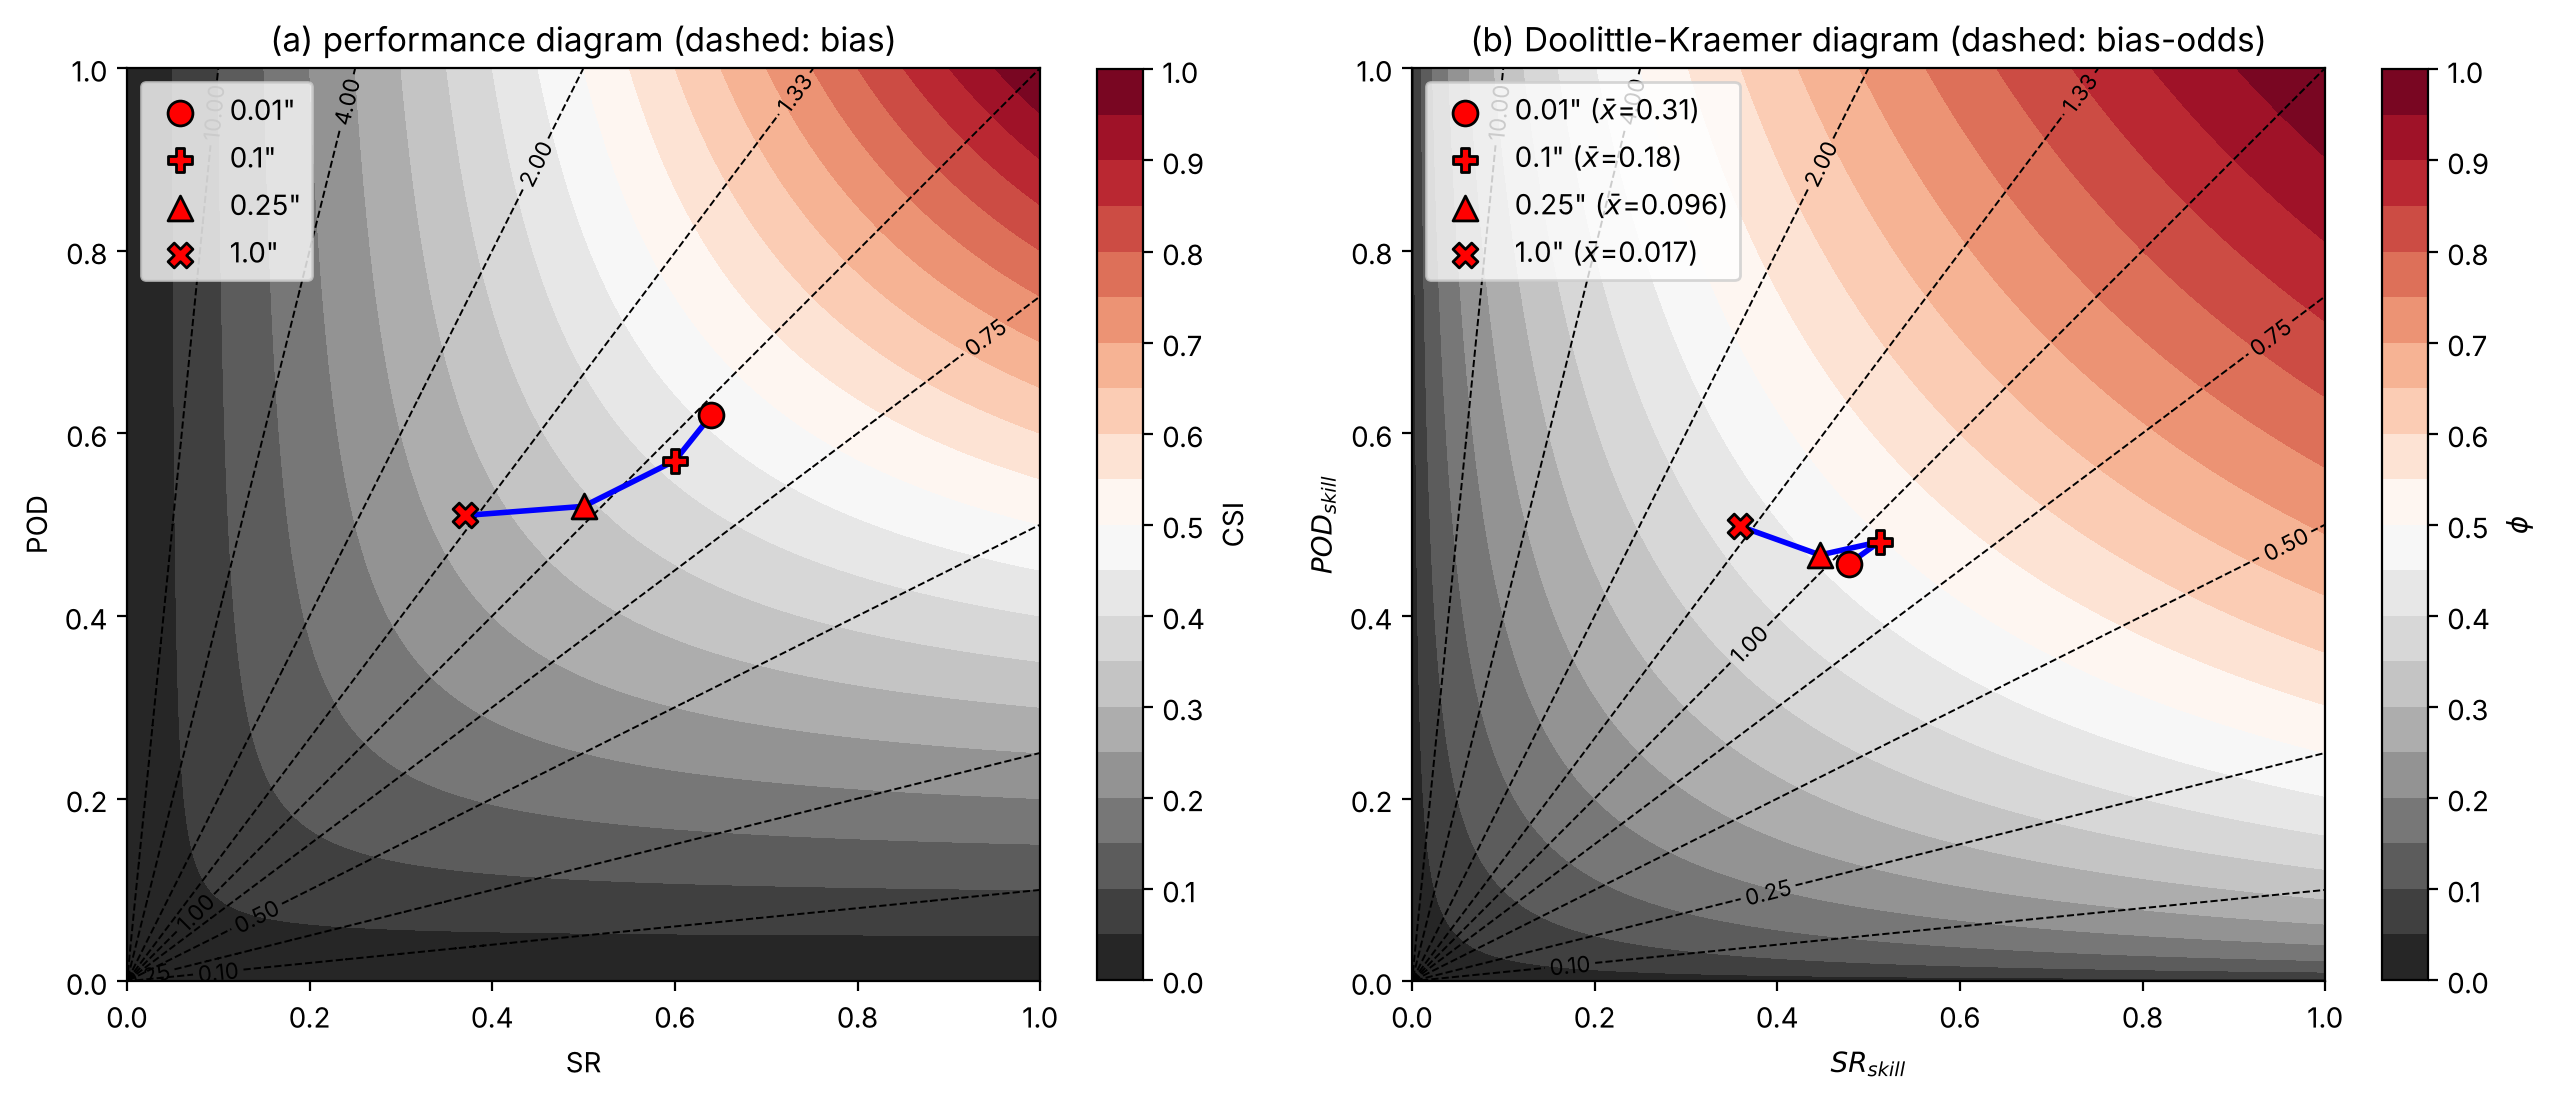

In [14]:

# [added] Fig. 4: LFM QPF thresholds, performance diagram vs Doolittle-Kraemer diagram
markers=['o','P','^','X']
pod_qpf=np.array([0.62,0.57,0.52,0.51]); sr_qpf=np.array([0.64,0.60,0.50,0.37])
xbar_qpf=np.array([0.31,0.18,0.096,0.017]); thr1=np.array([0.01,0.1,0.25,1.0])
aq,bq,cq,dq=t_from_podsr(pod_qpf,sr_qpf,xbar_qpf); pods_q,srs_q=skills(aq,bq,cq,dq)
fig,axs=plt.subplots(1,2,figsize=(13,6))
a,b,c,d=t_from_podsr(G_P,G_S,xbar_qpf[0])
cs=axs[0].contour(g1,g1,(a+b)/(a+c),levels=LV,colors='k',linestyles='dashed',linewidths=0.7); axs[0].clabel(cs,cs.levels,inline=True,fontsize=8)
sc=axs[0].contourf(g1,g1,a/(a+b+c),levels=np.linspace(0,1,21),cmap='RdGy_r')
plt.colorbar(sc,ax=axs[0],shrink=0.8,label='CSI',ticks=np.linspace(0,1,11))
axs[0].plot(sr_qpf,pod_qpf,c='b',lw=2,zorder=5)
for i in range(4): axs[0].scatter(sr_qpf[i],pod_qpf[i],facecolor='r',edgecolor='k',s=80,marker=markers[i],label=f'{thr1[i]}"',zorder=6)
axs[0].set(xlabel='SR',ylabel='POD',title='(a) performance diagram (dashed: bias)')
cs=axs[1].contour(g1,g1,G_P/G_S,levels=LV,colors='k',linestyles='dashed',linewidths=0.7); axs[1].clabel(cs,cs.levels,inline=True,fontsize=8)
sc=axs[1].contourf(g1,g1,np.sqrt(G_P*G_S),levels=np.linspace(0,1,21),cmap='RdGy_r')
plt.colorbar(sc,ax=axs[1],shrink=0.8,label=r'$\phi$',ticks=np.linspace(0,1,11))
axs[1].plot(srs_q,pods_q,c='b',lw=2,zorder=5)
for i in range(4): axs[1].scatter(srs_q[i],pods_q[i],facecolor='r',edgecolor='k',s=80,marker=markers[i],label=f'{thr1[i]}" ('+r'$\bar x$='+f'{xbar_qpf[i]})',zorder=6)
axs[1].set(xlabel=r'$SR_{skill}$',ylabel=r'$POD_{skill}$',title='(b) Doolittle-Kraemer diagram (dashed: bias-odds)')
for ax in axs: ax.set_aspect('equal'); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.legend(loc='upper left')
plt.tight_layout(); fig.savefig('figures/fig04.pdf',bbox_inches='tight')


In [15]:

# [added] tornado-warning duration data (H. Brooks): 51 offices, groups 0-4 = shortest to longest mean duration
offices=pd.DataFrame({'SR':[0.439331, 0.546493, 0.490196, 0.203046, 0.532178, 0.369369, 0.322936, 0.268124, 0.441057, 0.370262, 0.307836, 0.417891, 0.304762, 0.496528, 0.217557, 0.416323, 0.384289, 0.418919, 0.168067, 0.402957, 0.321238, 0.259053, 0.242215, 0.334443, 0.324153, 0.403061, 0.337917, 0.356989, 0.260563, 0.329412, 0.200581, 0.131757, 0.148594, 0.209169, 0.266212, 0.292419, 0.239300, 0.326761, 0.158798, 0.262338, 0.422492, 0.204774, 0.266174, 0.365801, 0.223919, 0.343042, 0.339806, 0.185442, 0.271930, 0.231683, 0.202667],'POD':[0.745020, 0.636842, 0.696721, 0.565891, 0.642857, 0.634981, 0.651408, 0.642857, 0.563380, 0.658537, 0.576433, 0.661871, 0.539773, 0.479167, 0.608856, 0.673077, 0.611650, 0.459615, 0.483871, 0.494670, 0.690537, 0.617647, 0.504425, 0.624615, 0.534173, 0.525806, 0.482412, 0.518106, 0.466912, 0.483986, 0.478632, 0.479452, 0.426523, 0.413793, 0.578947, 0.581395, 0.629213, 0.530973, 0.463235, 0.545946, 0.593407, 0.467532, 0.466102, 0.495298, 0.462069, 0.431280, 0.502890, 0.566667, 0.431818, 0.473510, 0.435065],'group':[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]})
groups=pd.DataFrame({'SR':[0.378249,0.358330,0.312704,0.232092,0.253417],'POD':[0.657924,0.575433,0.542804,0.529574,0.474539],'group':[0,1,2,3,4]})
colorlist=['#023EFF','#FF7C00','#1AC938','#E8000B','#8B2BE2']; legw=['#1-10','#11-20','#21-31','#32-41','#42-51']
def add_sk(dfin,x):
    out=dfin.copy(); a,b,c,d=t_from_podsr(out.POD.values,out.SR.values,x)
    out['PODs'],out['SRs']=skills(a,b,c,d); return out
def groups_on(ax,xcol,ycol,o,g):
    for i in range(5):
        oi=o[o.group==i]; mi=g[g.group==i].iloc[0]
        for _,r in oi.iterrows(): ax.plot([mi[xcol],r[xcol]],[mi[ycol],r[ycol]],color=colorlist[i],marker='o',ms=3,lw=0.5,alpha=0.5)
        ax.plot(mi[xcol],mi[ycol],'o',color=colorlist[i],ms=9,zorder=10,label=legw[i])
def dk_panel(ax,x,cbar=True,alpha_axes=True,title=None):
    a,b,c,d=t_from_skill(G_S,G_P,x)
    dp=norm.ppf(a/(a+c))-norm.ppf(b/(b+d))
    sc=ax.contourf(g1,g1,dp,levels=np.linspace(0,4,21),cmap='RdGy_r',extend='max')
    if cbar: plt.colorbar(sc,ax=ax,shrink=0.7,pad=0.12 if alpha_axes else 0.05,label=r"$D'$",ticks=np.linspace(0,4,5))
    cs=ax.contour(g1,g1,(a+b)/(a+c),levels=[0.25,0.5,0.75,1.,1.5,2.,4.],colors='k',linestyles='dashed',linewidths=0.8); ax.clabel(cs,cs.levels,inline=True,fontsize=8)
    o,g=add_sk(offices,x),add_sk(groups,x); groups_on(ax,'SRs','PODs',o,g)
    if alpha_axes:
        sx=ax.secondary_xaxis('top',functions=(lambda s:(1-x)*s+x,lambda u:(u-x)/(1-x))); sx.set_xlabel(r'$\alpha_{upper}$')
        sy=ax.secondary_yaxis('right',functions=(lambda s:x*(1-s),lambda u:1-u/x)); sy.set_ylabel(r'$\alpha_{lower}$')
    ax.set(xlim=(0,1),ylim=(0,1),aspect='equal',xlabel=r'$SR_{skill}$',ylabel=r'$POD_{skill}$')
    if title is None: title=r'(b) Doolittle-Kraemer diagram, $\bar x$ = '+f'{x}'
    if title: ax.set_title(title,pad=28 if alpha_axes else 6)
    ax.legend(loc='upper left',fontsize=8)


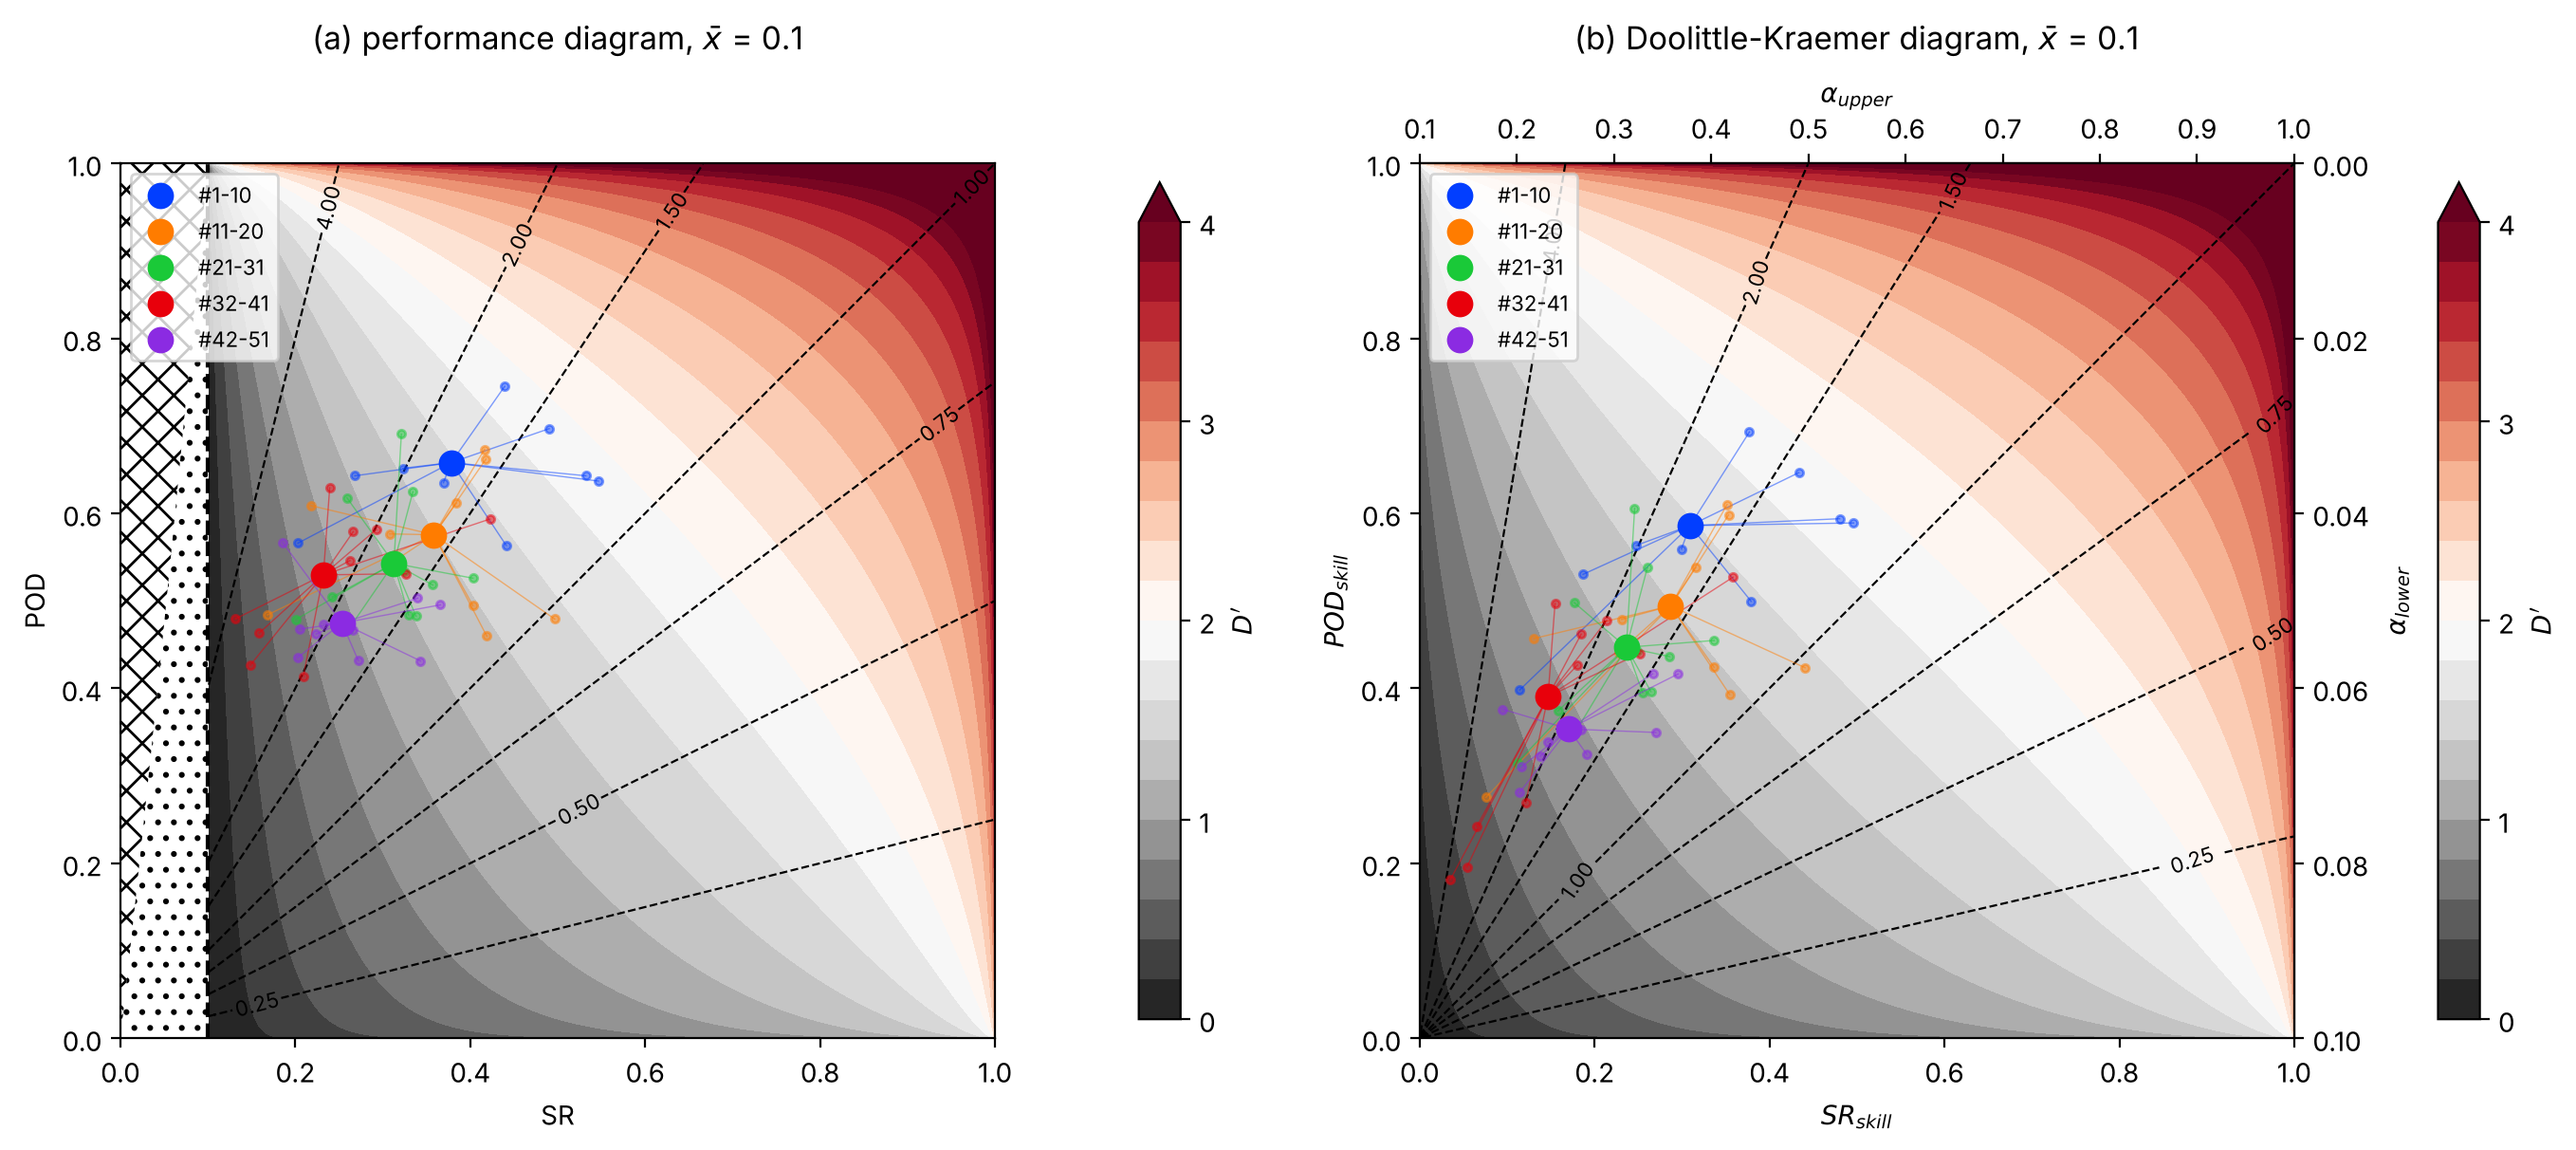

In [16]:

# [added] Fig. 5: warning-duration groups, performance diagram vs Doolittle-Kraemer diagram (xbar = 0.1)
x=0.1
fig,axs=plt.subplots(1,2,figsize=(14,6.6))
a,b,c,d=t_from_podsr(G_P,G_S,x); ns=G_S<=x
dp=norm.ppf(a/(a+c))-norm.ppf(b/(b+d)); dp[ns]=np.nan
cs=axs[0].contour(g1,g1,np.where(ns,np.nan,G_P/G_S),levels=[0.25,0.5,0.75,1.,1.5,2.,4.],colors='k',linestyles='dashed',linewidths=0.8); axs[0].clabel(cs,cs.levels,inline=True,fontsize=8)
sc=axs[0].contourf(g1,g1,dp,levels=np.linspace(0,4,21),cmap='RdGy_r',extend='max')
plt.colorbar(sc,ax=axs[0],shrink=0.7,pad=0.12,label=r"$D'$",ticks=np.linspace(0,4,5))
srmin=x*g1/(1-x+x*g1)
axs[0].add_patch(patches.Polygon(np.array([np.append(srmin,[0,0]),np.append(g1,[1,0])]).T,hatch='xx',fill=None,lw=0,zorder=3))
axs[0].add_patch(patches.Polygon(np.array([np.append(srmin,[x,0]),np.append(g1,[0,0])]).T,hatch='..',fill=None,lw=0,zorder=-5))
axs[0].plot([x,x],[0,1],'k--')
groups_on(axs[0],'SR','POD',offices,groups)
axs[0].set(xlim=(0,1),ylim=(0,1),aspect='equal',xlabel='SR',ylabel='POD'); axs[0].text(0.5,1.13,r'(a) performance diagram, $\bar x$ = 0.1',transform=axs[0].transAxes,ha='center',fontsize=12)
axs[0].legend(loc='upper left',fontsize=8)
dk_panel(axs[1],x,title='')
axs[1].text(0.5,1.13,r'(b) Doolittle-Kraemer diagram, $\bar x$ = 0.1',transform=axs[1].transAxes,ha='center',fontsize=12)
plt.tight_layout(); fig.savefig('figures/fig05.pdf',bbox_inches='tight')


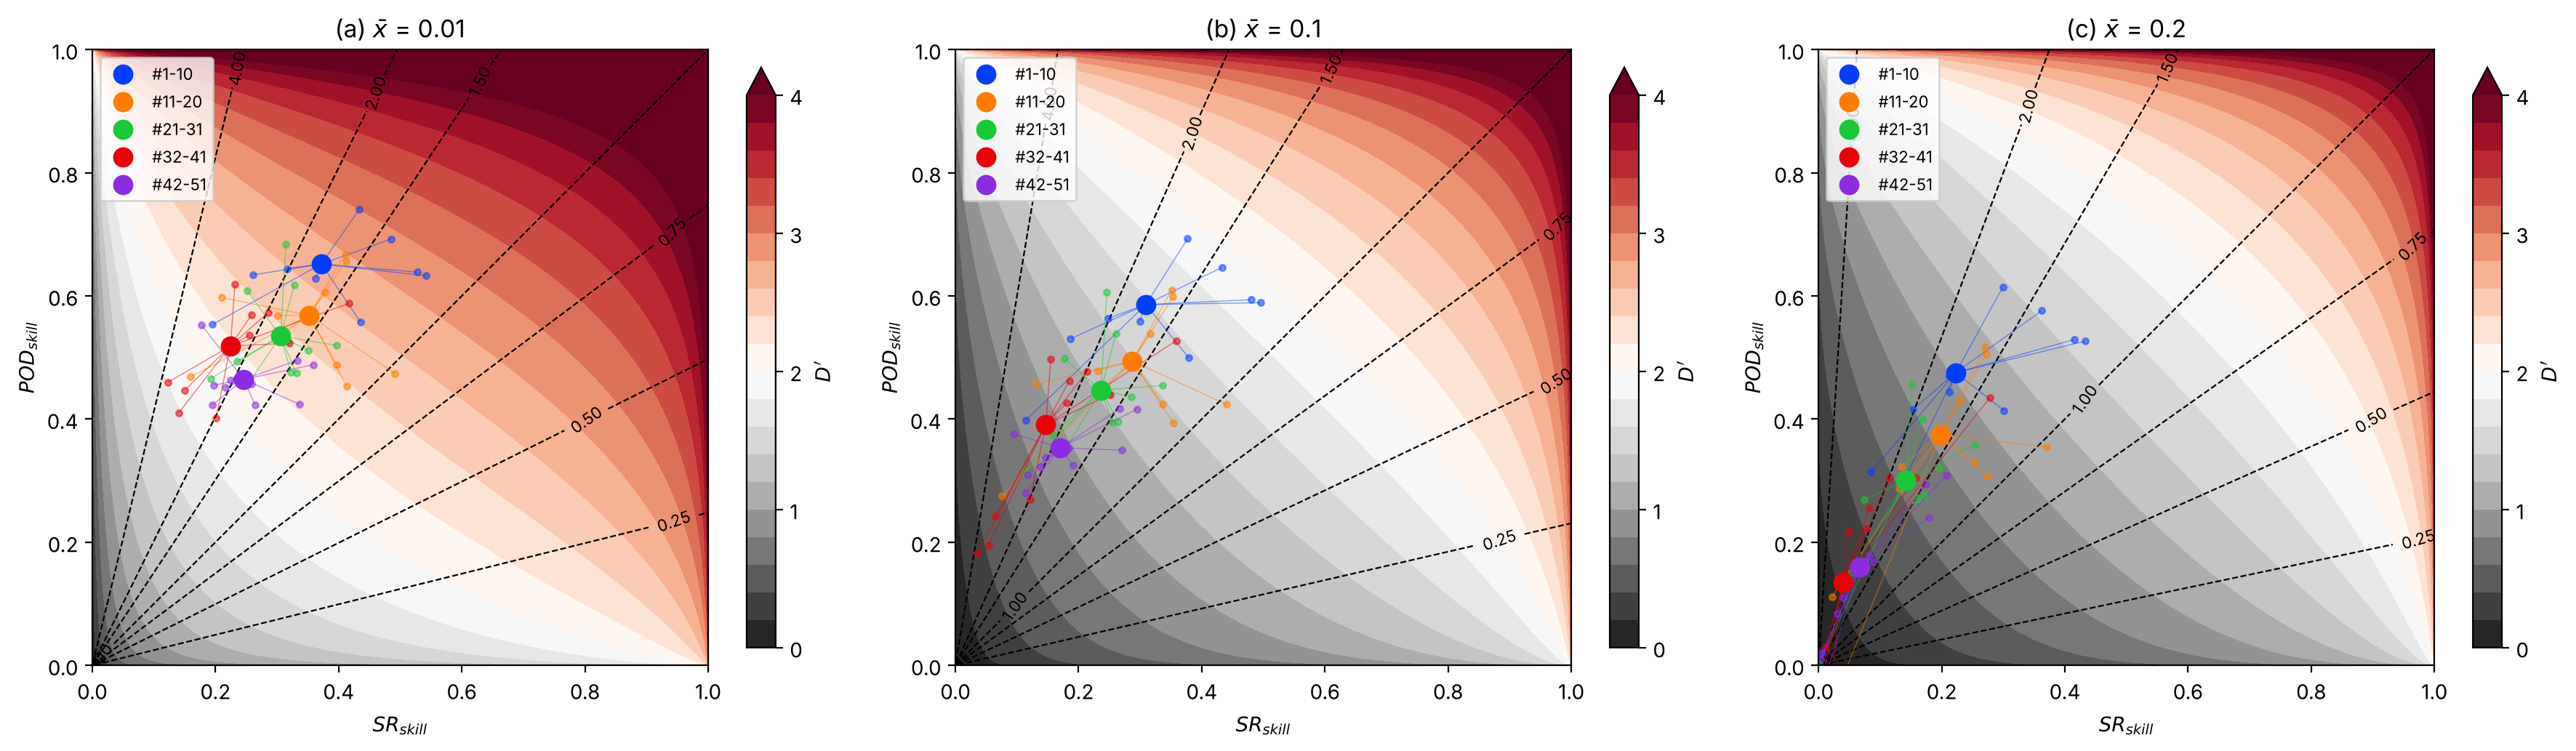

In [17]:

# [added] Fig. 6: sensitivity of the Doolittle-Kraemer display to the assumed base rate
fig,axs=plt.subplots(1,3,figsize=(18,6))
for ax,xb,lab in zip(axs,[0.01,0.1,0.2],['a','b','c']):
    dk_panel(ax,xb,cbar=True,alpha_axes=False,title=f'({lab}) '+r'$\bar x$ = '+f'{xb}')
plt.tight_layout(); fig.savefig('figures/fig06.pdf',bbox_inches='tight')
